# 🏭 SurfaceGuard AI — final notebook (Kaggle Version 5)
**DL & GenAI Project (T3-2026)** · Roll no. `23f3001567` · W&B project: `23f3001567-t32026`

## What this notebook does
Trains and compares **six U-Net models** (scratch, ResNet34, EfficientNet-B0/B2/B3, EfficientNet-B2 #2), tunes the decision rules on the official competition metric, adds 4-view TTA and ensembles three EfficientNets.
In this run **no saved weights were attached, so all six models were trained here** (≈ 5 h on a Tesla T4). The code can still re-load `*_best.pth` files found under `/kaggle/input` to save time.

## Results of this run
| Item | Value |
|---|---|
| Scratch U-Net → ResNet34 → best EfficientNet (simple rule, validation) | 0.6808 → 0.7003 → 0.7357 |
| Best single model with tuned rules + TTA (EfficientNet-B3) | 0.7489 |
| **Final ensemble B0 + B3 + B2 #2 (validation)** | **0.7554** |
| **Kaggle leaderboard (this version)** | **0.69878** (previous versions on Kaggle: 0.64888, 0.68774) |

## Rubric map
| Rubric component | Where in this notebook |
|---|---|
| ≥ 3 models incl. scratch + pretrained | Sections 5–8: scratch U-Net, ResNet34-U-Net, EfficientNet-B0/B2/B3/B2 #2 — Table 1 |
| ≥ 3 valid W&B runs | one run per trained model + `final_comparison_v5`; Section 12 counts them |
| Code walkthrough & live coding | comments in every cell, Section 13, `scripts/rle_metric.py` |
| Notebook / GitHub evaluation | metric self-check, RLE proof, ablation, error analysis, requirements |
| Report | Section 13 maps each report section to a cell; tables saved as CSV |


### ✅ Kaggle settings before "Run All"
1. **Add Input:** the competition data. (Optional: earlier notebooks whose output folders contain `effb0_best.pth`, `effb2_best.pth`, `effb3_best.pth`, `effb2b_best.pth`, so these models are re-loaded instead of retrained; Section 7 prints which weights were found.)
2. **Accelerator: GPU T4**, **Internet: ON** (downloads ImageNet weights), **Secrets → `WANDB_API_KEY`**, share the notebook (private) with **`dlgenaiproject`**.
3. Run time with nothing re-loaded: **≈ 5 h** (scratch 55 min, ResNet34 31 min, EfficientNet-B0 60 min, B2 44 min, B3 58 min, B2 #2 44 min, then ≈ 10 min ensemble search and test prediction).
4. Optional dry run: `QUICK_TEST = True` (~10 min), then back to `False`.
5. *Save Version → Save & Run All (Commit)* → read Sections 9 and 12 → submit `submission.csv`.


## 1. Setup — settings, libraries, reproducibility

In [1]:
# ===================== SETTINGS (the only things you may edit) =====================
ROLL_NO        = "23f3001567"
WANDB_PROJECT  = f"{ROLL_NO}-t32026"        # project name required by the course
QUICK_TEST     = False                      # True = tiny dry run (few images, 1 epoch) just to check the code
USE_PRETRAINED = True                       # True = download ImageNet weights (Internet ON)
INPUT_ROOT, OUT_DIR = "/kaggle/input", "/kaggle/working"

SEED, BATCH_SIZE, VAL_FRACTION = 42, 16, 0.2     # keep IDENTICAL to notebooks 11/22 -> identical validation images (needed to re-use their weights)
EPOCHS = {"scratch": 20, "resnet34": 15, "effb0": 30, "effb2": 18, "effb3": 20, "effb2b": 18}   # training length per model (scratch/resnet34 shortened to keep the run ~1h40)
LR     = {"scratch": 1e-3, "resnet34": 5e-4, "effb0": 5e-4, "effb2": 4e-4, "effb3": 4e-4, "effb2b": 4e-4}
USE_EMA, EMA_DECAY = True, 0.998            # exponential moving average of the weights (smoother, generalises better)

USE_MODELS = ["scratch", "resnet34", "effb0", "effb2", "effb3", "effb2b"]   # ALL six models are trained / loaded / evaluated here (rubric: >= 3 models, 1 scratch + 1 pretrained)
MAX_SOURCES = 2                                                          # how many saved training runs per model to load (v3 + v4 outputs)
ENSEMBLE_MODELS = ["effb0", "effb3", "effb2b"]                  # architectures that enter the ensemble (B2 never helped). Every saved run of each is loaded -> 6 members. scratch / resnet34 / effb2 are compared in Table 1
REUSABLE   = {"effb0", "effb2", "effb3", "effb2b"}      # looked up as <name>_best.pth under /kaggle/input; if found -> NOT retrained (scratch & resnet34 are ALWAYS trained here)
SEEDS      = {"effb3": 11, "effb2b": 23}                # own random seed for the new models (the train/validation split keeps SEED = 42!)
STRONG_AUG = {"effb2b"}                                 # models trained with the extra random shift + zoom augmentation
QUICK_N, QUICK_TEST_N = 300, 64

import os, time, random, json, warnings, math, copy, itertools, shutil
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torchvision
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm
warnings.filterwarnings("ignore")

H, W    = 128, 800                                                 # every image is 128 high x 800 wide
CLASSES = ["defect_a", "defect_b", "defect_c", "defect_d"]
NC      = len(CLASSES)
COLORS  = [(255, 60, 60), (255, 170, 0), (60, 140, 255), (60, 220, 90)]

if QUICK_TEST:
    BATCH_SIZE, EPOCHS = 8, {k: 1 for k in EPOCHS}

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything()

device  = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"
torch.backends.cudnn.benchmark = True
os.makedirs(OUT_DIR, exist_ok=True)
print("device:", device, "|", torch.cuda.get_device_name(0) if USE_AMP else "NO GPU -> switch on the T4 accelerator!")

device: cuda | Tesla T4


## 2. Data — find the files, read the labels, understand RLE
`train.csv` has **one row per (image, defect)**; `mask_rle` is empty when that defect is absent.
**RLE** = `start length start length …`: "from pixel *start*, the next *length* pixels are defect".
In this competition pixels are numbered **column by column** (column-major) and **starting from 1**.
We prove our encoder/decoder is right by decoding real labels and encoding them back: the text must be identical.

In [2]:
# ---- find the data automatically (the Kaggle folder name can differ) ----
IMG_EXT = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")

def find_file(root, names):
    for dirpath, _, files in os.walk(root):
        for n in names:
            if n in files: return os.path.join(dirpath, n)

def find_image_folder(root, split):                                # folder called 'train' / 'test' that holds the images
    best = None
    for dirpath, _, files in os.walk(root):
        if os.path.basename(dirpath) == split:
            n = sum(f.lower().endswith(IMG_EXT) for f in files)
            if n and (best is None or n > best[1]): best = (dirpath, n)
    return best[0] if best else None

def index_images(folder):                                          # {"image_id": "path/to/image_id.png"}
    return {os.path.splitext(f)[0]: os.path.join(folder, f) for f in os.listdir(folder) if f.lower().endswith(IMG_EXT)}

TRAIN_CSV  = find_file(INPUT_ROOT, ["train.csv", "train_1.csv"])
SAMPLE_CSV = find_file(INPUT_ROOT, ["sample_submission.csv", "sample_submission_1.csv"])
train_dir, test_dir = find_image_folder(INPUT_ROOT, "train"), find_image_folder(INPUT_ROOT, "test")
assert TRAIN_CSV and SAMPLE_CSV and train_dir and test_dir, "Data not found - did you click 'Add Input' and add the competition?"
TRAIN_PATHS, TEST_PATHS = index_images(train_dir), index_images(test_dir)
print(f"train images: {len(TRAIN_PATHS)} | test images: {len(TEST_PATHS)} | train.csv: {TRAIN_CSV}")

train images: 11393 | test images: 3000 | train.csv: /kaggle/input/competitions/industrial-surface-defect-detection/public/train.csv


In [3]:
# ---- RLE <-> mask ----
def rle_to_mask(rle, shape=(H, W)):
    # 'start length start length ...'  ->  0/1 array (H, W)
    flat = np.zeros(shape[0] * shape[1], dtype=np.uint8)
    if isinstance(rle, str) and rle.strip():
        nums = np.array(rle.split(), dtype=np.int64)
        for s, l in zip(nums[0::2] - 1, nums[1::2]):              # "- 1" because RLE counts from 1
            flat[s:s + l] = 1
    return flat.reshape(shape, order="F")                          # "F" = column-major order

def mask_to_rle(mask):
    # 0/1 array (H, W) -> 'start length ...' ('' if empty)
    pixels = np.concatenate([[0], mask.flatten(order="F"), [0]])   # padding handles a run that ends on the last pixel
    runs = np.where(pixels[1:] != pixels[:-1])[0] + 1              # positions where the value changes
    runs[1::2] -= runs[::2]                                        # end positions -> lengths
    return " ".join(str(x) for x in runs)

# ---- label tables ----
train_df  = pd.read_csv(TRAIN_CSV)
sample_df = pd.read_csv(SAMPLE_CSV, keep_default_na=False)         # keep the " " (= empty mask) exactly as in the sample
rle_pivot = train_df.pivot(index="image_id", columns="defect_type", values="mask_rle")[CLASSES].fillna("")
if QUICK_TEST: rle_pivot = rle_pivot.sample(min(QUICK_N, len(rle_pivot)), random_state=SEED)
has       = (rle_pivot != "").astype(int)                          # 0/1 table: does image X contain defect Y?
rle_table = {i: list(r) for i, r in zip(rle_pivot.index, rle_pivot.values)}
all_ids   = list(has.index)

# ---- proof that RLE is correct: decode -> encode must give the same text ----
real = train_df.mask_rle.dropna()
assert all(mask_to_rle(rle_to_mask(r)) == r for r in real.sample(min(500, len(real)), random_state=SEED))
print("✅ RLE encode/decode round-trip is exact on real labels")

print(f"\n{len(all_ids)} images | {100 * (has.sum(axis=1) == 0).mean():.1f}% have NO defect at all")
print("images containing each defect (%):", (has.mean() * 100).round(1).to_dict())

✅ RLE encode/decode round-trip is exact on real labels

11393 images | 48.4% have NO defect at all
images containing each defect (%): {'defect_a': 9.5, 'defect_b': 2.7, 'defect_c': 36.0, 'defect_d': 15.0}


### Look at the data (figures for the report)
Left: how often each defect appears (**class imbalance** — `defect_b` is rare, most images are clean).
Right: one example per defect; the coloured area is the true mask.

  0%|          | 0/11393 [00:00<?, ?it/s]

loaded 11393 images in 9s | each (128, 800) (high x wide)


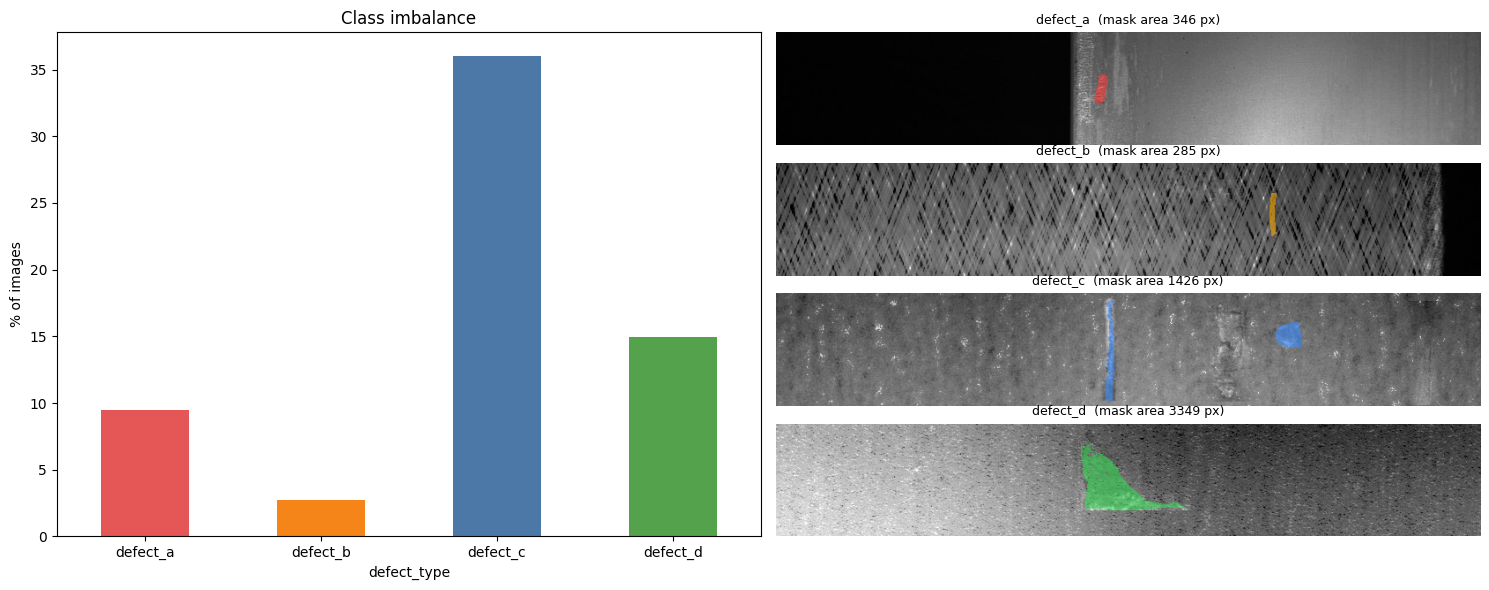

In [4]:
t0 = time.time()
def load_gray(path):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)                   # 1 channel, values 0..255
    return img if img.shape == (H, W) else cv2.resize(img, (W, H), interpolation=cv2.INTER_AREA)

def load_many(ids, path_map):                                      # read all images once into RAM -> fast training
    with ThreadPoolExecutor(8) as ex:
        return dict(zip(ids, tqdm(ex.map(lambda i: load_gray(path_map[i]), ids), total=len(ids), leave=False)))

missing = [i for i in all_ids if i not in TRAIN_PATHS]
assert not missing, f"{len(missing)} ids of train.csv have no image file (e.g. {missing[:3]}) - check file names in {train_dir}"
images = load_many(all_ids, TRAIN_PATHS)
print(f"loaded {len(images)} images in {time.time() - t0:.0f}s | each {next(iter(images.values())).shape} (high x wide)")

fig = plt.figure(figsize=(15, 6))
ax = fig.add_subplot(1, 2, 1); (has.mean() * 100).plot.bar(ax=ax, color=["#e45756", "#f58518", "#4c78a8", "#54a24b"], rot=0)
ax.set_ylabel("% of images"); ax.set_title("Class imbalance")
for c, cls in enumerate(CLASSES):                                  # one example per defect, stacked on the right
    iid = np.random.RandomState(c).choice(list(has.index[has[cls] == 1]))
    img, m = images[iid], rle_to_mask(rle_table[iid][c])
    rgb = np.stack([img] * 3, -1).copy(); rgb[m == 1] = (0.4 * rgb[m == 1] + 0.6 * np.array(COLORS[c])).astype(np.uint8)
    a = fig.add_subplot(4, 2, 2 * c + 2); a.imshow(rgb); a.axis("off"); a.set_title(f"{cls}  (mask area {int(m.sum())} px)", fontsize=9)
plt.tight_layout(); plt.show()

### Train / validation split (stratified)
We keep 20 % of the images aside as **validation** (to choose the best epoch and tune thresholds). An image can have several defects, so we split by the **whole pattern**
(e.g. `0101` = defect_b + defect_d) — this keeps the rare defect in both parts.

In [5]:
pattern = has.astype(str).agg("".join, axis=1)
pattern = pattern.where(pattern.map(pattern.value_counts()) >= 3, "rare")          # merge tiny patterns so the split never fails
train_ids, val_ids = train_test_split(all_ids, test_size=VAL_FRACTION, stratify=pattern.loc[all_ids], random_state=SEED)
print(f"train {len(train_ids)} | validation {len(val_ids)}")
print(pd.DataFrame({"train %": has.loc[train_ids].mean() * 100, "val %": has.loc[val_ids].mean() * 100}).round(2).T.to_string())

train 9114 | validation 2279
defect_type  defect_a  defect_b  defect_c  defect_d
train %          9.49      2.74     35.99     14.98
val %            9.48      2.76     35.98     15.01


## 3. Metric — the OFFICIAL competition score
`Score = 0.70 × ForegroundDice + 0.20 × FalsePositiveScore + 0.10 × EmptyAccuracy` (Milestone 1, Q8)
* **ForegroundDice** = mean Dice over (image, defect) pairs whose true mask is non-empty.
* **FalsePositiveScore** = `1 − mean(predicted pixels / 102 400)` over pairs whose true mask is empty → a false alarm is punished **in proportion to its size**, so a small stray blob costs almost nothing here.
* **EmptyAccuracy** = share of empty pairs where we predicted exactly nothing.

Consequence (the key insight of v2): one missed defect loses up to `0.7/n_fg` while one small false alarm only loses ≈ `0.1/n_empty` (≈ 27× less, because 84 % of pairs are empty). The best decision rule is therefore **recall-oriented** (low thresholds, small min-area).
Pixel accuracy is always ≈ 99 %, so we only report it for completeness.

In [6]:
def competition_score(inter, pa, ga):
    # inter / pa / ga : arrays (N images, 4 defects) of overlap, predicted and true pixel counts
    inter, pa, ga = [np.asarray(a, dtype=np.float64) for a in (inter, pa, ga)]
    has_defect = ga > 0
    dice    = 2 * inter / np.maximum(pa + ga, 1)
    fg_dice = dice[has_defect].mean() if has_defect.any() else 0.0
    if (~has_defect).any():
        fp_score  = 1 - (pa[~has_defect] / (H * W)).mean()          # 1 - mean false-positive pixel fraction
        empty_acc = (pa[~has_defect] == 0).mean()                   # predicted an entirely empty mask
    else:
        fp_score = empty_acc = 1.0
    tp, fp, fn = inter.sum(0), pa.sum(0) - inter.sum(0), ga.sum(0) - inter.sum(0)
    return dict(score=0.7 * fg_dice + 0.2 * fp_score + 0.1 * empty_acc, fg_dice=fg_dice, fp_score=fp_score, quiet=empty_acc,
                macro_f1=float(np.mean(2 * tp / np.maximum(2 * tp + fp + fn, 1))),
                pixel_acc=float(np.mean(1 - (fp + fn) / (len(inter) * H * W))),
                per_class_dice=[float(dice[has_defect[:, c], c].mean()) if has_defect[:, c].any() else 0.0 for c in range(inter.shape[1])])

# check against the worked example of Milestone Q8: 10 positive pairs (6 x Dice 0.8, 4 x Dice 0.4) + 40 empty pairs (4 false blobs of 1024 px)
ga_t    = np.r_[np.full(10, 1000), np.zeros(40)][:, None]
pa_t    = np.r_[np.full(10, 1000), np.full(4, 1024), np.zeros(36)][:, None]
inter_t = np.r_[np.full(6, 800), np.full(4, 400), np.zeros(40)][:, None]
m = competition_score(inter_t, pa_t, ga_t)
assert abs(m["score"] - 0.7378) < 5e-4, m
print(f"Q8 check: fg_dice {m['fg_dice']:.4f}, fp_score {m['fp_score']:.4f}, empty_acc {m['quiet']:.4f}, score {m['score']:.4f}  (expected 0.6400 0.9990 0.9000 0.7378)")
print("predict-nothing baseline on the real labels:", round(competition_score(np.zeros(has.shape), np.zeros(has.shape), has.values)["score"], 4), "(should be 0.30)")

Q8 check: fg_dice 0.6400, fp_score 0.9990, empty_acc 0.9000, score 0.7378  (expected 0.6400 0.9990 0.9000 0.7378)
predict-nothing baseline on the real labels: 0.3 (should be 0.30)


## 4. Dataset & DataLoader
- **Dataset** = recipe that returns *(image, 4 masks)* for index *i*. Pixels are normalised (0-255 → 0-1 → subtract mean, divide by std).
- **Augmentation** (training only): random horizontal / vertical flip, brightness and contrast jitter (same flip on image and masks). It shows the model "new" versions of the data → less over-fitting.
- **Strong augmentation (new in v3, only for Model 6)**: random sideways shift (±12 %), up/down shift (±6 %) and zoom (±10 %) — the *same* warp is applied to the image and its masks.
- **DataLoader** = delivers batches of 16 images to the GPU.
- **Weighted sampler**: images with rare defects are drawn more often (otherwise the model mostly sees clean images).
- Validation is *never* augmented or re-weighted.

one batch -> images (16, 1, 128, 800) | masks (16, 4, 128, 800) | validation masks (2279, 4, 128, 800)


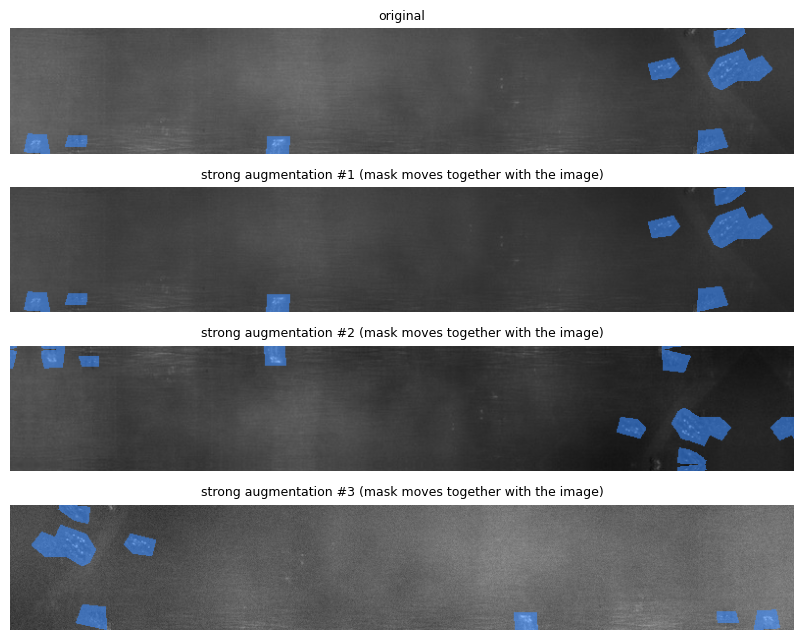

In [7]:
sub = np.stack([images[i] for i in train_ids[:2000]]).astype(np.float32) / 255.0
PIX_MEAN, PIX_STD = float(sub.mean()), float(sub.std()); del sub        # computed on training images only

def normalize_batch(arr_uint8):                                         # (B, H, W) uint8 -> (B, 1, H, W) float tensor
    return torch.from_numpy((arr_uint8.astype(np.float32) / 255.0 - PIX_MEAN) / PIX_STD)[:, None]

class DefectDataset(Dataset):
    def __init__(self, ids, augment=False, strong=False):
        self.ids, self.augment, self.strong = list(ids), augment, strong
    def __len__(self):
        return len(self.ids)
    def __getitem__(self, i):
        iid   = self.ids[i]
        img   = images[iid].astype(np.float32) / 255.0                             # (H, W)
        masks = np.stack([rle_to_mask(r) for r in rle_table[iid]])                 # (4, H, W) decoded from RLE
        if self.augment:
            if random.random() < 0.5: img, masks = img[:, ::-1], masks[:, :, ::-1]   # horizontal flip
            if random.random() < 0.5: img, masks = img[::-1, :], masks[:, ::-1, :]   # vertical flip
            if self.strong and random.random() < 0.7:                                # NEW (v3): random shift + zoom, SAME warp for image and masks
                zoom = random.uniform(0.9, 1.1)
                tx = (1 - zoom) * W / 2 + random.uniform(-0.12, 0.12) * W            # up to +-96 px sideways
                ty = (1 - zoom) * H / 2 + random.uniform(-0.06, 0.06) * H           # up to +-8 px up / down
                M = np.array([[zoom, 0, tx], [0, zoom, ty]], dtype=np.float32)
                img = cv2.warpAffine(np.ascontiguousarray(img), M, (W, H), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT_101)
                masks = np.stack([cv2.warpAffine(np.ascontiguousarray(m), M, (W, H), flags=cv2.INTER_NEAREST, borderMode=cv2.BORDER_REFLECT_101) for m in masks])
            img = np.clip(img, 0, 1) ** random.uniform(0.8, 1.25)                              # gamma (illumination change)
            img = np.clip(img * random.uniform(0.75, 1.25) + random.uniform(-0.12, 0.12), 0, 1) # contrast, brightness
            if random.random() < 0.3: img = np.clip(img + np.random.normal(0, 0.02, img.shape), 0, 1)   # sensor noise
        img = (img - PIX_MEAN) / PIX_STD
        return torch.from_numpy(np.ascontiguousarray(img))[None].float(), torch.from_numpy(np.ascontiguousarray(masks)).float()

freq     = has.loc[train_ids].mean()                                            # how common is each defect
weights  = 1 + (has.loc[train_ids] * (0.25 / freq)).sum(axis=1).values          # rarer defect -> bigger weight
WORKERS  = max(1, min(3, (os.cpu_count() or 2) - 1)) if USE_AMP else 0

def make_train_loader(strong=False):                                            # a fresh loader per model (weighted sampler: rare defects drawn more often)
    sampler = WeightedRandomSampler(weights, num_samples=len(train_ids), replacement=True)
    return DataLoader(DefectDataset(train_ids, augment=True, strong=strong), batch_size=BATCH_SIZE, sampler=sampler, num_workers=WORKERS,
                      pin_memory=True, drop_last=True, persistent_workers=WORKERS > 0)
val_loader = DataLoader(DefectDataset(val_ids), batch_size=32, shuffle=False, num_workers=WORKERS, pin_memory=True)

val_gt = torch.from_numpy(np.stack([np.stack([rle_to_mask(r) for r in rle_table[i]]) for i in val_ids]))   # (N_val, 4, H, W) true masks
x, y = next(iter(DataLoader(DefectDataset(train_ids, augment=True), batch_size=BATCH_SIZE, shuffle=True, num_workers=0)))
print("one batch -> images", tuple(x.shape), "| masks", tuple(y.shape), "| validation masks", tuple(val_gt.shape))

# look at the new strong augmentation: original + 3 random versions (image with its mask in colour)
iid = next(i for i in train_ids if rle_table[i][2] != "")                       # an image that contains defect_c
fig, axes = plt.subplots(4, 1, figsize=(14, 6.5))
for k, ax in enumerate(axes):
    ds = DefectDataset([iid], augment=(k > 0), strong=(k > 0))
    im, mk = ds[0]; im = np.clip(im[0].numpy() * PIX_STD + PIX_MEAN, 0, 1)
    rgb = np.stack([im] * 3, -1); rgb[mk[2].numpy() > 0.5] = 0.4 * rgb[mk[2].numpy() > 0.5] + 0.6 * np.array(COLORS[2]) / 255
    ax.imshow(rgb); ax.axis("off"); ax.set_title("original" if k == 0 else f"strong augmentation #{k} (mask moves together with the image)", fontsize=9)
plt.tight_layout(); plt.show()

## 5. Models — six U-Nets (scratch → pretrained → ensemble)
A **U-Net** shrinks the image (**encoder** = *what*) and grows it back (**decoder** = *where*); skip connections keep the detail. The last layer gives **4 sigmoid maps** (one per defect).

| # | Model | Encoder | Status in v4 |
|---|---|---|---|
| 1 | `SimpleUNet` | random weights (**scratch**) | **trained in this notebook** (own W&B run) — the baseline that shows what pre-training is worth |
| 2 | U-Net + **ResNet34** | ImageNet (**pretrained**) | **trained in this notebook** (own W&B run) |
| 3 | U-Net + **EfficientNet-B0** | ImageNet | re-loaded from the 0.69807 run (or trained here) — ensemble member |
| 4 | U-Net + **EfficientNet-B2** | ImageNet | re-loaded (or trained here) — tried in the ensemble search |
| 5 | U-Net + **EfficientNet-B3** | ImageNet | re-loaded (or trained here) — ensemble member |
| 6 | U-Net + **EfficientNet-B2 #2** | ImageNet | re-loaded (or trained here): other seed + shift/zoom augmentation — ensemble member |

*Design story for the report:* scratch (does the task need pre-training?) → ResNet34 (a standard pretrained encoder) → EfficientNets (better accuracy per parameter) → ensemble (different models make different mistakes).
*Grayscale trick:* the first conv of every pretrained encoder is replaced by a 1-channel conv whose weights are the sum of the 3 colour weights.


In [8]:
class ConvBlock(nn.Sequential):                                          # (3x3 conv -> BatchNorm -> ReLU) twice
    def __init__(self, cin, cout):
        super().__init__(nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
                         nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))

class SimpleUNet(nn.Module):                                             # MODEL 1: U-Net from scratch
    def __init__(self, base=32):
        super().__init__()
        c = [base, base * 2, base * 4, base * 8, base * 16]              # 32, 64, 128, 256, 512 channels
        self.enc = nn.ModuleList([ConvBlock(1, c[0]), ConvBlock(c[0], c[1]), ConvBlock(c[1], c[2]), ConvBlock(c[2], c[3])])
        self.bottom = ConvBlock(c[3], c[4])
        self.pool = nn.MaxPool2d(2)                                      # halves height and width
        self.up  = nn.ModuleList([nn.ConvTranspose2d(c[i + 1], c[i], 2, stride=2) for i in range(4)])   # learnable up-sampling x2
        self.dec = nn.ModuleList([ConvBlock(c[i] * 2, c[i]) for i in range(4)])
        self.head = nn.Conv2d(c[0], NC, 1)
        nn.init.constant_(self.head.bias, -4.0)                          # start at "~2 % probability" (defects are rare) -> stable start
    def forward(self, x):
        skips = []
        for enc in self.enc:                                             # ENCODER: go down, remember every level
            x = enc(x); skips.append(x); x = self.pool(x)
        x = self.bottom(x)
        for i in (3, 2, 1, 0):                                           # DECODER: go up, add the remembered level (skip connection)
            x = self.dec[i](torch.cat([self.up[i](x), skips[i]], 1))
        return self.head(x)                                              # raw scores (logits) (B, 4, H, W)

class DecoderBlock(nn.Module):
    def __init__(self, cin, cskip, cout):
        super().__init__(); self.conv = ConvBlock(cin + cskip, cout)
    def forward(self, x, skip):
        x = F.interpolate(x, size=skip.shape[-2:], mode="bilinear", align_corners=False)   # up-sample to the skip's size
        return self.conv(torch.cat([x, skip], 1))

class PretrainedUNet(nn.Module):                                         # pretrained encoder + U-Net decoder
    def __init__(self, arch, enc_ch=None, pretrained=True):
        super().__init__()
        w = "IMAGENET1K_V1" if pretrained else None
        try:
            if arch == "resnet34":
                m = torchvision.models.resnet34(weights=w)
                m.conv1 = self._to_gray(m.conv1)
                self.stages = nn.ModuleList([nn.Sequential(m.conv1, m.bn1, m.relu), nn.Sequential(m.maxpool, m.layer1), m.layer2, m.layer3, m.layer4])
                enc_ch = [64, 64, 128, 256, 512]
            else:                                                        # efficientnet_b0 / b2 / b3 (same stage layout, different widths)
                m = getattr(torchvision.models, arch)(weights=w)
                m.features[0][0] = self._to_gray(m.features[0][0]); f = m.features
                self.stages = nn.ModuleList([f[0:2], f[2], f[3], f[4:6], f[6:8]])
        except Exception as e:
            raise RuntimeError("Could not get the pretrained weights - turn Internet ON in the notebook settings.") from e
        dec_ch, prev, self.decoder = [256, 128, 64, 32], enc_ch[-1], nn.ModuleList()
        for cskip, cout in zip(enc_ch[-2::-1], dec_ch):
            self.decoder.append(DecoderBlock(prev, cskip, cout)); prev = cout
        self.final, self.head = ConvBlock(prev, 16), nn.Conv2d(16, NC, 1)
        nn.init.constant_(self.head.bias, -4.0)
    @staticmethod
    def _to_gray(conv):                                                  # 3-channel conv -> 1-channel conv (weights summed)
        new = nn.Conv2d(1, conv.out_channels, conv.kernel_size, conv.stride, conv.padding, bias=False)
        new.weight.data = conv.weight.data.sum(1, keepdim=True); return new
    def forward(self, x):
        feats = []
        for stage in self.stages:
            x = stage(x); feats.append(x)
        d = feats[-1]
        for block, skip in zip(self.decoder, reversed(feats[:-1])):
            d = block(d, skip)
        d = F.interpolate(d, scale_factor=2, mode="bilinear", align_corners=False)
        return self.head(self.final(d))

EFF = {"effb0":  ("efficientnet_b0", [16, 24, 40, 112, 320]),
       "effb2":  ("efficientnet_b2", [16, 24, 48, 120, 352]),
       "effb2b": ("efficientnet_b2", [16, 24, 48, 120, 352]),
       "effb3":  ("efficientnet_b3", [24, 32, 48, 136, 384])}          # channels of the 5 encoder stages (stride 2, 4, 8, 16, 32)
MODEL_INFO = {"scratch":  ("model1_scratch_v5",    "Model 1: U-Net from scratch (random weights)"),
              "resnet34": ("model2_resnet34_v5",   "Model 2: U-Net + ResNet34 (ImageNet pretrained)"),
              "effb0":    ("model3_effnetb0",      "Model 3: U-Net + EfficientNet-B0 (ImageNet pretrained, EMA + pair-Dice loss)"),
              "effb2":    ("model4_effnetb2_v2",   "Model 4: U-Net + EfficientNet-B2 (ImageNet pretrained, EMA + pair-Dice loss)"),
              "effb3":    ("model5_effnetb3_v3",   "Model 5: U-Net + EfficientNet-B3 (ImageNet pretrained, EMA + pair-Dice loss)"),
              "effb2b":   ("model6_effnetb2b_v3",  "Model 6: U-Net + EfficientNet-B2 #2 (new seed + shift/zoom augmentation)")}
def build_model(name, pretrained=True):
    if name == "scratch":  return SimpleUNet()
    if name == "resnet34": return PretrainedUNet("resnet34", None, pretrained)
    arch, ch = EFF[name]; return PretrainedUNet(arch, ch, pretrained)

for n in ["scratch", "resnet34", "effb3"]:                                             # check: (2,1,128,800) image in -> (2,4,128,800) scores out
    net = build_model(n, pretrained=False).eval()
    with torch.no_grad(): out = net(torch.zeros(2, 1, H, W))
    print(f"{MODEL_INFO[n][1]:<80} output {tuple(out.shape)} | {sum(p.numel() for p in net.parameters()) / 1e6:.1f} M parameters")
    del net

Model 1: U-Net from scratch (random weights)                                     output (2, 4, 128, 800) | 7.8 M parameters
Model 2: U-Net + ResNet34 (ImageNet pretrained)                                  output (2, 4, 128, 800) | 24.4 M parameters
Model 5: U-Net + EfficientNet-B3 (ImageNet pretrained, EMA + pair-Dice loss)     output (2, 4, 128, 800) | 12.6 M parameters


## 6. Training tools
- **Loss = BCE + ½·batch-Dice + ½·per-pair Dice.** The per-pair term is the Dice of every (image, defect) pair that really contains a defect — exactly what 70 % of the score measures — so small defects are not drowned by big ones.
- **AdamW**, 1-epoch linear **warm-up** then **cosine** decay, **gradient clipping**, **mixed precision (AMP)**.
- **EMA** of the weights: the averaged weights are what we validate and save (less noisy, generalise better).
- After every epoch the *official* score is measured on the validation set and the best epoch is kept.
- **Post-processing = 3 rules per defect (v3):** (1) *threshold*: a pixel is defect if its probability > threshold, (2) *minimum area*: fewer pixels than that → noise → empty mask, (3) **confidence gate (new)**: the most confident pixel of the mask must reach the gate, otherwise the whole mask is dropped.

In [9]:
# ---------- Weights & Biases login (key comes from the Kaggle secret WANDB_API_KEY) ----------
try:
    from kaggle_secrets import UserSecretsClient
    import wandb
    wandb.login(key=UserSecretsClient().get_secret("WANDB_API_KEY"))
    print("✅ W&B login OK, project:", WANDB_PROJECT)
except Exception as e:
    os.environ["WANDB_MODE"] = "disabled"; import wandb
    print("⚠️ W&B is DISABLED (", repr(e)[:80], ") -> add the secret WANDB_API_KEY, otherwise your runs are NOT recorded!")

# ---------- loss ----------
bce = nn.BCEWithLogitsLoss()
def dice_loss(logits, target, eps=1.0):
    p = torch.sigmoid(logits)
    inter, denom = (p * target).sum((0, 2, 3)), p.sum((0, 2, 3)) + target.sum((0, 2, 3))
    batch_dice = 1 - ((2 * inter + eps) / (denom + eps)).mean()                    # one number per defect type (as before)
    i2, d2 = (p * target).sum((2, 3)), p.sum((2, 3)) + target.sum((2, 3))          # (B, 4) per image x defect pair
    pos = (target.sum((2, 3)) > 0).float()                                         # pairs that really contain a defect
    pair_dice = (((1 - (2 * i2 + eps) / (d2 + eps)) * pos).sum() / pos.sum().clamp(min=1))
    return 0.5 * batch_dice + 0.5 * pair_dice
def criterion(logits, target):
    logits = logits.float()
    return bce(logits, target) + dice_loss(logits, target)

# ---------- turning probabilities into masks: threshold + minimum area + confidence gate ----------
@torch.no_grad()
def postprocess(prob, thr, min_area, gate=0.0):
    # prob (B,4,H,W). thr / min_area / gate: one number or a list of 4 (one per defect type)
    thr      = torch.as_tensor(thr, dtype=torch.float32, device=prob.device).reshape(1, -1, 1, 1)
    min_area = torch.as_tensor(min_area, dtype=torch.float32, device=prob.device).reshape(1, -1)
    gate     = torch.as_tensor(gate, dtype=torch.float32, device=prob.device).reshape(1, -1)
    prob = prob.float()
    pred = prob > thr                                                    # 1) threshold: "how sure must I be before I draw this pixel?"
    area = pred.sum((2, 3)).float()
    top  = prob.amax((2, 3))                                             # most confident pixel of every (image, defect) pair
    keep = (area >= min_area) & (area > 0) & (top >= gate)               # 2) too few pixels -> noise;  3) not confident anywhere -> empty mask
    return pred & keep[:, :, None, None]

@torch.no_grad()
def stats_from_probs(prob, gt, thr, min_area, gate=0.0, chunk=128):    # prob, gt: (N,4,H,W) on CPU -> tables inter / pa / ga (N,4)
    I, P, G = [], [], []
    for s in range(0, len(prob), chunk):
        pred, g = postprocess(prob[s:s + chunk].to(device), thr, min_area, gate), gt[s:s + chunk].to(device).bool()
        I.append((pred & g).sum((2, 3)).cpu()); P.append(pred.sum((2, 3)).cpu()); G.append(g.sum((2, 3)).cpu())
    return torch.cat(I).numpy(), torch.cat(P).numpy(), torch.cat(G).numpy()

@torch.no_grad()
def validate(model, loader, thr=0.4, min_area=40):                      # quick validation used after every epoch (official score)
    model.eval(); losses, I, P, G = [], [], [], []
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(x)
        losses.append(criterion(logits, y).item() * len(x))
        pred, g = postprocess(torch.sigmoid(logits.float()), thr, min_area), y.bool()
        I.append((pred & g).sum((2, 3)).cpu()); P.append(pred.sum((2, 3)).cpu()); G.append(g.sum((2, 3)).cpu())
    m = competition_score(torch.cat(I).numpy(), torch.cat(P).numpy(), torch.cat(G).numpy())
    m["loss"] = sum(losses) / len(loader.dataset)
    return m

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


✅ W&B login OK, project: 23f3001567-t32026


In [10]:
class EMA:                                                               # exponential moving average of all weights and BN statistics
    def __init__(self, model, decay):
        self.module, self.decay, self.steps = copy.deepcopy(model).eval(), decay, 0
        for p in self.module.parameters(): p.requires_grad_(False)
    @torch.no_grad()
    def update(self, model):
        self.steps += 1; d = min(self.decay, (1 + self.steps) / (10 + self.steps))   # short warm-up of the averaging
        for e, m in zip(self.module.state_dict().values(), model.state_dict().values()):
            if e.dtype.is_floating_point: e.mul_(d).add_(m.detach(), alpha=1 - d)
            else: e.copy_(m)

def train_model(name, model, loader, strong=False):
    run_name, description = MODEL_INFO[name]
    n_params = sum(p.numel() for p in model.parameters())
    wandb.init(project=WANDB_PROJECT, name=run_name, reinit=True,        # ---- one W&B run per model ----
               config=dict(model=description, epochs=EPOCHS[name], lr=LR[name], batch_size=BATCH_SIZE, params_M=round(n_params / 1e6, 2),
                           loss="BCE + 0.5 batch Dice + 0.5 pair Dice", optimizer="AdamW", scheduler="warm-up + cosine", ema=USE_EMA, amp=USE_AMP,
                           pretrained=(name != "scratch"), augmentation="flips+gamma+brightness+contrast+noise" + ("+shift+zoom" if strong else ""), metric="official 0.7/0.2/0.1", seed=SEEDS.get(name, SEED)))
    opt    = torch.optim.AdamW(model.parameters(), lr=LR[name], weight_decay=1e-4)
    steps_ep = len(loader); total, warm = EPOCHS[name] * steps_ep, steps_ep
    lr_fn  = lambda s: (s + 1) / warm if s < warm else 0.01 + 0.99 * 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm)))
    sched  = torch.optim.lr_scheduler.LambdaLR(opt, lr_fn)               # stepped after every batch
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    ema    = EMA(model, EMA_DECAY) if USE_EMA else None
    ckpt, best, history, t0 = f"{OUT_DIR}/{name}_best.pth", -1.0, [], time.time()
    for epoch in range(1, EPOCHS[name] + 1):
        model.train(); running = 0.0
        for x, y in tqdm(loader, desc=f"{name} epoch {epoch}", leave=False):
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
                logits = model(x)                                        # 1) forward pass
            loss = criterion(logits, y)                                  # 2) loss
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()                                # 3) backward pass
            scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            scaler.step(opt); scaler.update(); sched.step()              # 4) update weights, then LR
            if ema: ema.update(model)
            running += loss.item() * len(x)
        eval_model = ema.module if ema else model                        # validate / save the averaged weights
        val = validate(eval_model, val_loader)
        row = dict(epoch=epoch, train_loss=running / (steps_ep * BATCH_SIZE), val_loss=val["loss"], val_score=val["score"], val_fg_dice=val["fg_dice"],
                   val_macro_f1=val["macro_f1"], val_pixel_acc=val["pixel_acc"], lr=opt.param_groups[0]["lr"])
        history.append(row); wandb.log({**row, **{f"val_dice_{c}": d for c, d in zip(CLASSES, val["per_class_dice"])}})
        if val["score"] > best: best = val["score"]; torch.save(eval_model.state_dict(), ckpt); mark = "  <- best so far, saved"
        else: mark = ""
        print(f"[{name}] epoch {epoch:02d}/{EPOCHS[name]} | train_loss {row['train_loss']:.4f} | val_loss {row['val_loss']:.4f} | val_score {val['score']:.4f} "
              f"| fg_dice {val['fg_dice']:.3f} | F1 {val['macro_f1']:.3f} | {(time.time() - t0) / 60:.1f} min{mark}")
    model.load_state_dict(torch.load(ckpt, map_location=device))         # go back to the best epoch
    wandb.run.summary["best_val_score"] = best; wandb.finish()
    return pd.DataFrame(history)

# ---------- bookkeeping: trained models, their validation probabilities, results ----------
@torch.no_grad()
def predict_batch(model, x, tta=True):
    # TTA: 4 views (original, left-right, up-down, both flips) averaged
    def run(inp):
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
            return torch.sigmoid(model(inp).float())
    p = run(x)
    if not tta: return p
    return (p + run(x.flip(3)).flip(3) + run(x.flip(2)).flip(2) + run(x.flip(2, 3)).flip(2, 3)) / 4

@torch.no_grad()
def predict_val_probs(model):                                            # validation probabilities (with TTA), kept on the CPU as float16
    model.eval()
    return torch.cat([predict_batch(model, x.to(device)).half().cpu() for x, _ in val_loader])

MODELS, VAL_PROBS, RESULTS, HISTORY = {}, {}, {}, {}

def find_all_ckpts(name):                                                 # every saved <name>_best.pth under /kaggle/input (one per attached notebook)
    return sorted(os.path.join(d, f"{name}_best.pth") for d, _, fs in os.walk(INPUT_ROOT) if f"{name}_best.pth" in fs)
def find_ckpt(name):
    f = find_all_ckpts(name); return f[0] if f else None

def log_reused_run(key, saved, r):
    # weights were re-loaded -> still leave a clean, valid W&B run (config + metrics) so EVERY model has a run in this project
    run_name, description = MODEL_INFO[key]
    wandb.init(project=WANDB_PROJECT, name=run_name + "_eval_v5", reinit=True,
               config=dict(model=description, status="weights re-loaded from an earlier training run (not retrained here)", weights=saved,
                           params_M=round(r["params_M"], 2), pretrained=True, metric="official 0.7/0.2/0.1", rule="threshold 0.4, min area 40, no TTA"))
    wandb.log({"val_score": r["score"], "val_fg_dice": r["fg_dice"], "val_macro_f1": r["macro_f1"], "val_pixel_acc": r["pixel_acc"], "val_loss": r["loss"]})
    wandb.run.summary["best_val_score"] = r["score"]; wandb.finish()

def register(key, model, trained_here, saved=None):
    model.eval()
    RESULTS[key] = validate(model, val_loader) | {"params_M": sum(p.numel() for p in model.parameters()) / 1e6, "trained_here": trained_here}
    if saved: log_reused_run(key, saved, RESULTS[key])
    if key.split("#")[0] in ENSEMBLE_MODELS:                             # ensemble members keep their (large) validation probabilities
        MODELS[key] = model; VAL_PROBS[key] = predict_val_probs(model)
    else:
        MODELS[key] = model.cpu(); torch.cuda.empty_cache()
    r = RESULTS[key]; print(f"\n{key}: val_score {r['score']:.4f} | fg_dice {r['fg_dice']:.4f} | macro-F1 {r['macro_f1']:.4f} | pixel_acc {r['pixel_acc']:.4f}   (thr 0.4, min-area 40, no TTA)")

def run_experiment(name):
    print("=" * 90, "\n" + MODEL_INFO[name][1], "\n" + "=" * 90)
    seed_everything(SEEDS.get(name, SEED))
    paths = find_all_ckpts(name) if name in REUSABLE and not QUICK_TEST else []
    if paths:                                                            # re-load saved weights from earlier runs -> no training
        paths = paths[:MAX_SOURCES] if name in ENSEMBLE_MODELS else paths[:1]
        for k, p in enumerate(paths, 1):
            key = name if k == 1 else f"{name}#{k}"                      # effb0, effb0#2, ...
            run_name, desc = MODEL_INFO[name]
            MODEL_INFO[key] = (run_name if k == 1 else f"{run_name}_src{k}", desc + ("" if k == 1 else f"  [2nd saved training run]"))
            model = build_model(name, pretrained=False).to(device)
            model.load_state_dict(torch.load(p, map_location=device)); print(f"re-using saved weights (no training) -> {key}:", p)
            try: shutil.copy(p, f"{OUT_DIR}/{key.replace('#', '_src')}_best.pth")
            except Exception: pass
            register(key, model, False, p)
    else:                                                                # nothing saved (or scratch / resnet34) -> train here
        strong = name in STRONG_AUG
        loader = make_train_loader(strong)
        model = build_model(name, USE_PRETRAINED).to(device)
        HISTORY[name] = train_model(name, model, loader, strong); del loader
        register(name, model, True)


## 7. Models 1 – 6 (all six trained in this run)
Read the lines: `val_score` is the **official** score. With EMA the first epochs look lower than usual (averaging lags) and then overtake.
First a check of which saved weights were found (in this run none were attached, so every model is trained here):


In [11]:
print("Saved weights found in /kaggle/input (Add Input -> Notebooks -> Your work -> add BOTH the v3 and the v4 notebook):\n")
n_src = {}
for n in ENSEMBLE_MODELS + ["effb2"]:
    ps = find_all_ckpts(n) if n in REUSABLE else []; n_src[n] = len(ps)
    print(f"  {n:7s}: {len(ps)} saved run(s)" + "".join(f"\n            {p}" for p in ps) if ps else f"  {n:7s}: NOT FOUND -> will be TRAINED in this run")
print("  scratch / resnet34: always TRAINED in this run (rubric: the scratch and a pretrained model must be visible in this notebook)")
if any(v == 0 for v in n_src.values()):
    print("\n⛔ weights missing for", [k for k, v in n_src.items() if v == 0], "-> these will be RETRAINED (B0 ~60 min, B2 ~45, B3 ~57, B2b ~44) and the result will move by run-to-run noise.\n"
          "   Stop here, add the two notebooks as Input and run again, unless you really want a fresh training run.")
elif min(n_src[n] for n in ENSEMBLE_MODELS) < 2:
    print("\n⚠️  only ONE saved run per model found -> no fusion possible; this reproduces the earlier ensemble. Attach BOTH notebooks for the fusion.")
else:
    print("\n✅ two saved runs per ensemble model found -> v5 fuses them (6 members).")

Saved weights found in /kaggle/input (Add Input -> Notebooks -> Your work -> add BOTH the v3 and the v4 notebook):

  effb0  : NOT FOUND -> will be TRAINED in this run
  effb3  : NOT FOUND -> will be TRAINED in this run
  effb2b : NOT FOUND -> will be TRAINED in this run
  effb2  : NOT FOUND -> will be TRAINED in this run
  scratch / resnet34: always TRAINED in this run (rubric: the scratch and a pretrained model must be visible in this notebook)

⛔ weights missing for ['effb0', 'effb3', 'effb2b', 'effb2'] -> these will be RETRAINED (B0 ~60 min, B2 ~45, B3 ~57, B2b ~44) and the result will move by run-to-run noise.
   Stop here, add the two notebooks as Input and run again, unless you really want a fresh training run.


### Model 1 — U-Net from scratch (random weights) — the baseline
No pre-training: every weight starts random. This is the **scratch model** the rubric asks for and the reference that shows how much ImageNet pre-training helps. Trained for `EPOCHS["scratch"]` epochs with the same loss, EMA and validation as every other model, so the comparison is fair.

In [12]:
if "scratch" in USE_MODELS: run_experiment("scratch")

Model 1: U-Net from scratch (random weights) 


wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.
wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20261105_073031-loldd96w
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run model1_scratch_v5
wandb: ⭐️ View project at https://wandb.ai/iitm-mcq-sai/23f3001567-t32026
wandb: 🚀 View run at https://wandb.ai/iitm-mcq-sai/23f3001567-t32026/runs/loldd96w


scratch epoch 1:   0%|          | 0/569 [00:00<?, ?it/s]

[scratch] epoch 01/20 | train_loss 0.9102 | val_loss 0.7890 | val_score 0.5203 | fg_dice 0.406 | F1 0.183 | 3.2 min  <- best so far, saved


scratch epoch 2:   0%|          | 0/569 [00:00<?, ?it/s]

[scratch] epoch 02/20 | train_loss 0.7831 | val_loss 0.7152 | val_score 0.5646 | fg_dice 0.446 | F1 0.258 | 5.9 min  <- best so far, saved


... (35 outputs left out)

wandb: updating run metadata


[scratch] epoch 20/20 | train_loss 0.4281 | val_loss 0.5170 | val_score 0.6808 | fg_dice 0.571 | F1 0.509 | 54.8 min  <- best so far, saved


wandb: 
wandb: Run history:
wandb:             epoch ▁▁▂▂▂▃▃▄▄▄▅▅▅▆▆▇▇▇██
wandb:                lr ████▇▇▆▆▅▅▄▄▃▃▂▂▁▁▁▁
wandb:        train_loss █▆▅▅▄▄▄▃▃▃▃▂▂▂▂▁▁▁▁▁
wandb: val_dice_defect_a ▁▃▃▄▅▆▇▇▇███████████
wandb: val_dice_defect_b ▁▂▃▄▅▆▇▇██▇▇▇▆▆▅▅▅▅▄
wandb: val_dice_defect_c ▁▃▃▄▅▆▆▇▇▇▇█████████
wandb: val_dice_defect_d ▁▂▄▄▅▅▆▆▇▇▇▇████████
wandb:       val_fg_dice ▁▃▃▄▅▆▆▇▇▇██████████
wandb:          val_loss █▆▅▅▄▄▃▃▃▂▂▂▂▁▁▁▁▁▁▁
wandb:      val_macro_f1 ▁▃▃▄▄▅▅▆▆▆▇▇▇███████
wandb:                +2 ...
wandb: 
wandb: Run summary:
wandb:    best_val_score 0.68084
wandb:             epoch 20
wandb:                lr 1e-05
wandb:        train_loss 0.4281
wandb: val_dice_defect_a 0.39288
wandb: val_dice_defect_b 0.36457
wandb: val_dice_defect_c 0.58497
wandb: val_dice_defect_d 0.68766
wandb:       val_fg_dice 0.57091
wandb:          val_loss 0.51696
wandb:                +3 ...
wandb: 
wandb: 🚀 View run model1_scratch_v5 at: https://wandb.ai/iitm-mcq-sai/23f3001567-t32026/runs/lol


scratch: val_score 0.6808 | fg_dice 0.5709 | macro-F1 0.5090 | pixel_acc 0.9943   (thr 0.4, min-area 40, no TTA)


### Model 2 — U-Net + ResNet34 (ImageNet pretrained)
A classic pretrained encoder (residual blocks). Same decoder, loss and schedule → the *only* difference to Model 1 is the encoder and its pre-trained weights.

In [13]:
if "resnet34" in USE_MODELS: run_experiment("resnet34")

Model 2: U-Net + ResNet34 (ImageNet pretrained) 
Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 201MB/s]
wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20261105_082534-03bz7dvn
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run model2_resnet34_v5
wandb: ⭐️ View project at https://wandb.ai/iitm-mcq-sai/23f3001567-t32026
wandb: 🚀 View run at https://wandb.ai/iitm-mcq-sai/23f3001567-t32026/runs/03bz7dvn


resnet34 epoch 1:   0%|          | 0/569 [00:00<?, ?it/s]

[resnet34] epoch 01/15 | train_loss 0.8650 | val_loss 0.7224 | val_score 0.5912 | fg_dice 0.485 | F1 0.295 | 2.6 min  <- best so far, saved


resnet34 epoch 2:   0%|          | 0/569 [00:00<?, ?it/s]

[resnet34] epoch 02/15 | train_loss 0.7185 | val_loss 0.6470 | val_score 0.6223 | fg_dice 0.513 | F1 0.339 | 4.6 min  <- best so far, saved


... (24 outputs left out)

resnet34 epoch 15:   0%|          | 0/569 [00:00<?, ?it/s]

[resnet34] epoch 15/15 | train_loss 0.3919 | val_loss 0.4926 | val_score 0.7002 | fg_dice 0.589 | F1 0.543 | 31.0 min


wandb: updating run metadata
wandb: uploading history steps 14-14, summary, console lines 14-14
wandb: 
wandb: Run history:
wandb:             epoch ▁▁▂▃▃▃▄▅▅▅▆▇▇▇█
wandb:                lr ███▇▇▆▅▄▄▃▂▂▁▁▁
wandb:        train_loss █▆▅▄▄▃▃▃▂▂▂▁▁▁▁
wandb: val_dice_defect_a ▁▁▃▃▃▄▄▆▇▇▇████
wandb: val_dice_defect_b ▃▅▆▇█▇▆▆▆▆▅▄▃▂▁
wandb: val_dice_defect_c ▁▃▃▄▅▆▆▆▇▇▇████
wandb: val_dice_defect_d ▁▂▃▄▆▆▆▇▇▇▇████
wandb:       val_fg_dice ▁▃▄▄▅▆▆▆▇▇█████
wandb:          val_loss █▆▅▄▃▃▃▂▂▂▁▁▁▁▁
wandb:      val_macro_f1 ▁▂▃▄▅▅▆▆▇▇▇████
wandb:                +2 ...
wandb: 
wandb: Run summary:
wandb:    best_val_score 0.70031
wandb:             epoch 15
wandb:                lr 1e-05
wandb:        train_loss 0.39189
wandb: val_dice_defect_a 0.38106
wandb: val_dice_defect_b 0.31068
wandb: val_dice_defect_c 0.61685
wandb: val_dice_defect_d 0.70571
wandb:       val_fg_dice 0.58921
wandb:          val_loss 0.4926
wandb:                +3 ...
wandb: 
wandb: 🚀 View run model2_resnet34_v5 at: https://w


resnet34: val_score 0.7003 | fg_dice 0.5900 | macro-F1 0.5424 | pixel_acc 0.9952   (thr 0.4, min-area 40, no TTA)


### Model 3 — U-Net + EfficientNet-B0 (ImageNet pretrained; trained here, ≈ 60 min)


In [14]:
if "effb0" in USE_MODELS: run_experiment("effb0")

Model 3: U-Net + EfficientNet-B0 (ImageNet pretrained, EMA + pair-Dice loss) 
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 151MB/s]
wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20261105_085707-u83y81ow
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run model3_effnetb0
wandb: ⭐️ View project at https://wandb.ai/iitm-mcq-sai/23f3001567-t32026
wandb: 🚀 View run at https://wandb.ai/iitm-mcq-sai/23f3001567-t32026/runs/u83y81ow


effb0 epoch 1:   0%|          | 0/569 [00:00<?, ?it/s]

[effb0] epoch 01/30 | train_loss 0.8426 | val_loss 0.7096 | val_score 0.6165 | fg_dice 0.517 | F1 0.314 | 3.0 min  <- best so far, saved


effb0 epoch 2:   0%|          | 0/569 [00:00<?, ?it/s]

[effb0] epoch 02/30 | train_loss 0.6764 | val_loss 0.5856 | val_score 0.6674 | fg_dice 0.574 | F1 0.411 | 5.0 min  <- best so far, saved


... (54 outputs left out)

effb0 epoch 30:   0%|          | 0/569 [00:00<?, ?it/s]

[effb0] epoch 30/30 | train_loss 0.2789 | val_loss 0.4279 | val_score 0.7289 | fg_dice 0.624 | F1 0.594 | 59.9 min


wandb: updating run metadata
wandb: 
wandb: Run history:
wandb:             epoch ▁▁▁▂▂▂▂▃▃▃▃▄▄▄▄▅▅▅▅▆▆▆▆▇▇▇▇███
wandb:                lr █████▇▇▇▇▆▆▆▅▅▅▄▄▄▃▃▃▂▂▂▂▁▁▁▁▁
wandb:        train_loss █▆▅▄▄▄▃▃▃▃▃▃▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁
wandb: val_dice_defect_a ▁▆▇▆▇▇███████▇▇▇▇██▇███▇▇▇▇▇▇▇
wandb: val_dice_defect_b ▁▆▇█▇▇▆▇▇▆▅▅▄▅▄▄▄▄▄▄▃▃▃▃▃▃▃▃▃▃
wandb: val_dice_defect_c ▁▃▄▅▆▆▆▆▆▆▇▇▇▇▇███████████████
wandb: val_dice_defect_d ▁▄▄▅▅▆▆▆▇▇█▇▇█████████████▇███
wandb:       val_fg_dice ▁▅▅▆▇▇▇▇▇▇████████████████████
wandb:          val_loss █▅▄▃▃▃▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
wandb:      val_macro_f1 ▁▃▅▆▆▆▇▇▇▇▇▇██████████████████
wandb:                +2 ...
wandb: 
wandb: Run summary:
wandb:    best_val_score 0.73059
wandb:             epoch 30
wandb:                lr 1e-05
wandb:        train_loss 0.27894
wandb: val_dice_defect_a 0.40171
wandb: val_dice_defect_b 0.3276
wandb: val_dice_defect_c 0.65307
wandb: val_dice_defect_d 0.74996
wandb:       val_fg_dice 0.62416
wandb:          val_loss 0.42788
wand


effb0: val_score 0.7306 | fg_dice 0.6271 | macro-F1 0.5950 | pixel_acc 0.9962   (thr 0.4, min-area 40, no TTA)


### Model 4 — U-Net + EfficientNet-B2 (ImageNet pretrained; trained here, ≈ 44 min)


In [15]:
if "effb2" in USE_MODELS: run_experiment("effb2")

Model 4: U-Net + EfficientNet-B2 (ImageNet pretrained, EMA + pair-Dice loss) 
Downloading: "https://download.pytorch.org/models/efficientnet_b2_rwightman-c35c1473.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b2_rwightman-c35c1473.pth


100%|██████████| 35.2M/35.2M [00:00<00:00, 152MB/s]
wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20261105_095750-2pcnc5xb
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run model4_effnetb2_v2
wandb: ⭐️ View project at https://wandb.ai/iitm-mcq-sai/23f3001567-t32026
wandb: 🚀 View run at https://wandb.ai/iitm-mcq-sai/23f3001567-t32026/runs/2pcnc5xb


effb2 epoch 1:   0%|          | 0/569 [00:00<?, ?it/s]

[effb2] epoch 01/18 | train_loss 0.8594 | val_loss 0.6918 | val_score 0.6283 | fg_dice 0.537 | F1 0.336 | 3.6 min  <- best so far, saved


effb2 epoch 2:   0%|          | 0/569 [00:00<?, ?it/s]

[effb2] epoch 02/18 | train_loss 0.6568 | val_loss 0.5782 | val_score 0.6764 | fg_dice 0.584 | F1 0.429 | 6.0 min  <- best so far, saved


... (30 outputs left out)

effb2 epoch 18:   0%|          | 0/569 [00:00<?, ?it/s]

[effb2] epoch 18/18 | train_loss 0.3108 | val_loss 0.4366 | val_score 0.7305 | fg_dice 0.627 | F1 0.603 | 44.2 min


wandb: updating run metadata
wandb: uploading history steps 17-17, summary, console lines 17-17
wandb: 
wandb: Run history:
wandb:             epoch ▁▁▂▂▃▃▃▄▄▅▅▆▆▆▇▇██
wandb:                lr ███▇▇▇▆▅▅▄▄▃▂▂▂▁▁▁
wandb:        train_loss █▅▄▃▃▃▃▂▂▂▂▁▁▁▁▁▁▁
wandb: val_dice_defect_a ▁▆▆▇▇▆▇▇▇█████▇▇▇▇
wandb: val_dice_defect_b ▁▅▇█▇▇▇▇██▇▇▆▆▅▅▅▄
wandb: val_dice_defect_c ▁▄▄▄▅▆▆▇▇▇▇███████
wandb: val_dice_defect_d ▁▄▅▆▆▆▆▇▇██▇▇█████
wandb:       val_fg_dice ▁▄▅▆▆▆▇▇▇█████████
wandb:          val_loss █▅▄▃▂▂▂▂▁▁▁▁▁▁▁▁▁▁
wandb:      val_macro_f1 ▁▃▅▆▆▇▇▇██████████
wandb:                +2 ...
wandb: 
wandb: Run summary:
wandb:    best_val_score 0.73304
wandb:             epoch 18
wandb:                lr 0.0
wandb:        train_loss 0.31077
wandb: val_dice_defect_a 0.41982
wandb: val_dice_defect_b 0.40353
wandb: val_dice_defect_c 0.64636
wandb: val_dice_defect_d 0.75123
wandb:       val_fg_dice 0.62667
wandb:          val_loss 0.43655
wandb:                +3 ...
wandb: 
wandb: 🚀 View run mod


effb2: val_score 0.7330 | fg_dice 0.6321 | macro-F1 0.6041 | pixel_acc 0.9960   (thr 0.4, min-area 40, no TTA)


### Model 5 — U-Net + EfficientNet-B3 (ImageNet pretrained; trained here, ≈ 58 min)
Same recipe that made B2 a strong single model, with a bigger encoder.


In [16]:
if "effb3" in USE_MODELS: run_experiment("effb3")

Model 5: U-Net + EfficientNet-B3 (ImageNet pretrained, EMA + pair-Dice loss) 
Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b3_rwightman-b3899882.pth


100%|██████████| 47.2M/47.2M [00:00<00:00, 182MB/s]
wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20261105_104220-vpgqsgir
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run model5_effnetb3_v3
wandb: ⭐️ View project at https://wandb.ai/iitm-mcq-sai/23f3001567-t32026
wandb: 🚀 View run at https://wandb.ai/iitm-mcq-sai/23f3001567-t32026/runs/vpgqsgir


effb3 epoch 1:   0%|          | 0/569 [00:00<?, ?it/s]

[effb3] epoch 01/20 | train_loss 0.8765 | val_loss 0.6991 | val_score 0.6312 | fg_dice 0.514 | F1 0.348 | 4.1 min  <- best so far, saved


effb3 epoch 2:   0%|          | 0/569 [00:00<?, ?it/s]

[effb3] epoch 02/20 | train_loss 0.6634 | val_loss 0.5759 | val_score 0.6813 | fg_dice 0.593 | F1 0.427 | 6.9 min  <- best so far, saved


... (34 outputs left out)

effb3 epoch 20:   0%|          | 0/569 [00:00<?, ?it/s]

[effb3] epoch 20/20 | train_loss 0.2989 | val_loss 0.4198 | val_score 0.7347 | fg_dice 0.631 | F1 0.609 | 57.7 min  <- best so far, saved


wandb: updating run metadata
wandb: 
wandb: Run history:
wandb:             epoch ▁▁▂▂▂▃▃▄▄▄▅▅▅▆▆▇▇▇██
wandb:                lr ████▇▇▆▆▅▅▄▄▃▃▂▂▁▁▁▁
wandb:        train_loss █▅▄▃▃▃▃▂▂▂▂▂▁▁▁▁▁▁▁▁
wandb: val_dice_defect_a ▁▇▇▇▇▇▇███▇████▇▇▇▇▇
wandb: val_dice_defect_b ▁█████████▇▇▇▇▇▇▇▇▇▇
wandb: val_dice_defect_c ▁▅▅▅▆▆▇▇▇▇██▇███████
wandb: val_dice_defect_d ▁▄▅▅▅▆▇▆▇▇▇▇▇███████
wandb:       val_fg_dice ▁▆▆▆▇▇▇▇████████████
wandb:          val_loss █▅▄▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁
wandb:      val_macro_f1 ▁▃▅▆▆▇▇▇▇▇██████████
wandb:                +2 ...
wandb: 
wandb: Run summary:
wandb:    best_val_score 0.73469
wandb:             epoch 20
wandb:                lr 0.0
wandb:        train_loss 0.29886
wandb: val_dice_defect_a 0.42987
wandb: val_dice_defect_b 0.37706
wandb: val_dice_defect_c 0.64774
wandb: val_dice_defect_d 0.76545
wandb:       val_fg_dice 0.63119
wandb:          val_loss 0.41982
wandb:                +3 ...
wandb: 
wandb: 🚀 View run model5_effnetb3_v3 at: https://wandb.ai/iitm-mcq-s


effb3: val_score 0.7347 | fg_dice 0.6312 | macro-F1 0.6089 | pixel_acc 0.9963   (thr 0.4, min-area 40, no TTA)


### Model 6 — U-Net + EfficientNet-B2 #2 (trained here; other seed + shift/zoom augmentation, ≈ 44 min)
Same architecture as Model 4 but a *different* model: other random start, other batches, stronger augmentation. Averaging such models cancels their individual mistakes.


In [17]:
if "effb2b" in USE_MODELS: run_experiment("effb2b")

Model 6: U-Net + EfficientNet-B2 #2 (new seed + shift/zoom augmentation) 


wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20261105_114104-zdd7b0fm
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run model6_effnetb2b_v3
wandb: ⭐️ View project at https://wandb.ai/iitm-mcq-sai/23f3001567-t32026
wandb: 🚀 View run at https://wandb.ai/iitm-mcq-sai/23f3001567-t32026/runs/zdd7b0fm


effb2b epoch 1:   0%|          | 0/569 [00:00<?, ?it/s]

[effb2b] epoch 01/18 | train_loss 0.8608 | val_loss 0.7000 | val_score 0.6308 | fg_dice 0.528 | F1 0.319 | 2.4 min  <- best so far, saved


effb2b epoch 2:   0%|          | 0/569 [00:00<?, ?it/s]

[effb2b] epoch 02/18 | train_loss 0.6972 | val_loss 0.5957 | val_score 0.6639 | fg_dice 0.581 | F1 0.396 | 5.0 min  <- best so far, saved


... (30 outputs left out)

effb2b epoch 18:   0%|          | 0/569 [00:00<?, ?it/s]

[effb2b] epoch 18/18 | train_loss 0.3645 | val_loss 0.4338 | val_score 0.7357 | fg_dice 0.637 | F1 0.609 | 43.5 min  <- best so far, saved


wandb: updating run metadata
wandb: 
wandb: Run history:
wandb:             epoch ▁▁▂▂▃▃▃▄▄▅▅▆▆▆▇▇██
wandb:                lr ███▇▇▇▆▅▅▄▄▃▂▂▂▁▁▁
wandb:        train_loss █▆▄▄▃▃▃▂▂▂▂▂▁▁▁▁▁▁
wandb: val_dice_defect_a ▁▆▇▇▆▇▇▇▇▇▇▇██████
wandb: val_dice_defect_b ▁▇████████▇▇▇▇▇▇▇▇
wandb: val_dice_defect_c ▁▃▄▅▆▆▆▆▇▇▇▇██████
wandb: val_dice_defect_d ▁▃▄▅▅▆▆▆▇▇▇▇▇▇████
wandb:       val_fg_dice ▁▄▆▆▆▇▇▇▇▇▇███████
wandb:          val_loss █▅▄▃▃▂▂▂▂▂▁▁▁▁▁▁▁▁
wandb:      val_macro_f1 ▁▃▄▅▆▆▇▇▇▇▇▇██████
wandb:                +2 ...
wandb: 
wandb: Run summary:
wandb:    best_val_score 0.73571
wandb:             epoch 18
wandb:                lr 0.0
wandb:        train_loss 0.36453
wandb: val_dice_defect_a 0.44688
wandb: val_dice_defect_b 0.44626
wandb: val_dice_defect_c 0.65245
wandb: val_dice_defect_d 0.75404
wandb:       val_fg_dice 0.63673
wandb:          val_loss 0.43381
wandb:                +3 ...
wandb: 
wandb: 🚀 View run model6_effnetb2b_v3 at: https://wandb.ai/iitm-mcq-sai/23f3001567-t3202


effb2b: val_score 0.7357 | fg_dice 0.6367 | macro-F1 0.6088 | pixel_acc 0.9960   (thr 0.4, min-area 40, no TTA)


## 8. Compare the models (report: results table + ablation + learning curves)
Same validation images and the same simple rule (threshold 0.4, minimum area 40 px, no TTA), **official** score — so differences come from the *model*, not from tuning.

,type,params (M),trained in this run,val score,foreground Dice,macro F1,pixel accuracy
model,,,,,,,
Model 1: U-Net from scratch (random weights),scratch,7.8,True,0.6808,0.5709,0.5090,0.9943
Model 2: U-Net + ResNet34 (ImageNet pretrained),pretrained,24.4,True,0.7003,0.5900,0.5424,0.9952
"Model 3: U-Net + EfficientNet-B0 (ImageNet pretrained, EMA + pair-Dice loss)",pretrained,5.8,True,0.7306,0.6271,0.5950,0.9962
"Model 4: U-Net + EfficientNet-B2 (ImageNet pretrained, EMA + pair-Dice loss)",pretrained,9.5,True,0.7330,0.6321,0.6041,0.9960
"Model 5: U-Net + EfficientNet-B3 (ImageNet pretrained, EMA + pair-Dice loss)",pretrained,12.6,True,0.7347,0.6312,0.6089,0.9963
Model 6: U-Net + EfficientNet-B2 #2 (new seed + shift/zoom augmentation),pretrained,9.5,True,0.7357,0.6367,0.6088,0.9960


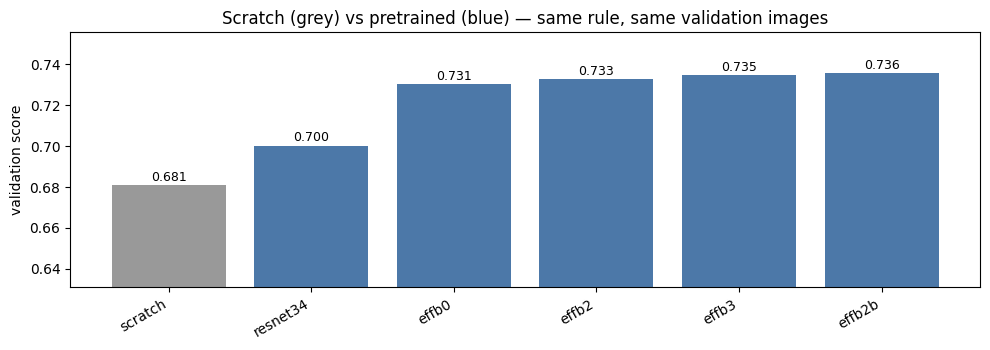

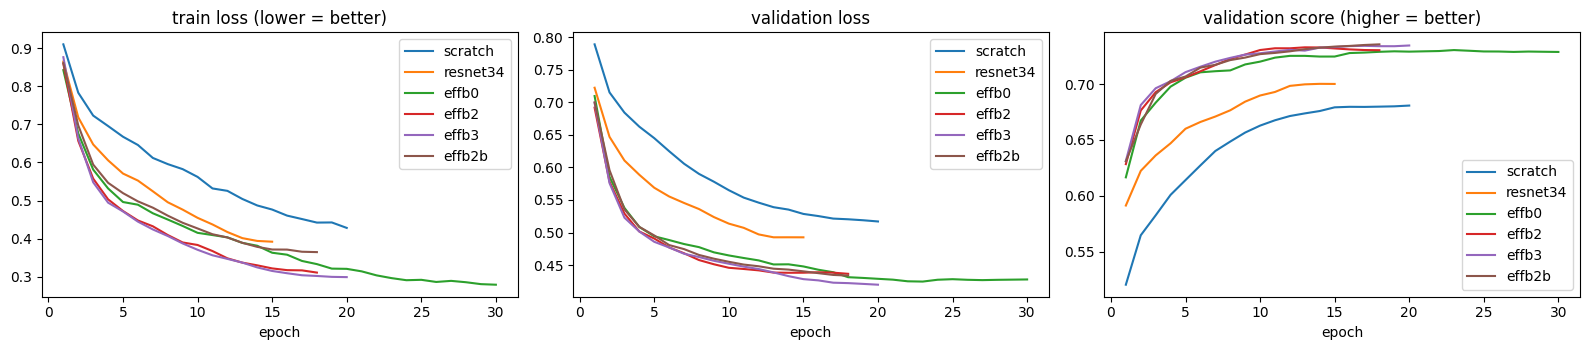

Reading the curves: the gap between train loss and validation loss shows over-fitting; the scratch model is the one that starts lowest and rises slowest.


In [18]:
table1 = pd.DataFrame([{"model": MODEL_INFO[n][1], "type": "scratch" if n == "scratch" else "pretrained", "params (M)": round(RESULTS[n]["params_M"], 1),
                        "trained in this run": RESULTS[n]["trained_here"], "val score": round(RESULTS[n]["score"], 4),
                        "foreground Dice": round(RESULTS[n]["fg_dice"], 4), "macro F1": round(RESULTS[n]["macro_f1"], 4),
                        "pixel accuracy": round(RESULTS[n]["pixel_acc"], 4)} for n in RESULTS]).set_index("model")
display(table1); table1.to_csv(f"{OUT_DIR}/table1_models.csv")

# ---- bar chart: scratch vs pretrained vs EfficientNets (same rule) ----
fig, ax = plt.subplots(figsize=(10, 3.6))
cols = ["#999999" if n == "scratch" else "#4c78a8" for n in RESULTS]
ax.bar(range(len(RESULTS)), [RESULTS[n]["score"] for n in RESULTS], color=cols)
ax.set_xticks(range(len(RESULTS))); ax.set_xticklabels(list(RESULTS), rotation=30, ha="right")
lo = min(RESULTS[n]["score"] for n in RESULTS); ax.set_ylim(max(0, lo - 0.05), max(RESULTS[n]["score"] for n in RESULTS) + 0.02)
for k, n in enumerate(RESULTS): ax.text(k, RESULTS[n]["score"] + 0.002, f"{RESULTS[n]['score']:.3f}", ha="center", fontsize=9)
ax.set_ylabel("validation score"); ax.set_title("Scratch (grey) vs pretrained (blue) — same rule, same validation images"); plt.tight_layout(); plt.show()

if HISTORY:                                                              # learning curves of the models trained in THIS run
    fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
    for n, h in HISTORY.items():
        ax[0].plot(h.epoch, h.train_loss, label=n); ax[1].plot(h.epoch, h.val_loss, label=n); ax[2].plot(h.epoch, h.val_score, label=n)
    for a, t in zip(ax, ["train loss (lower = better)", "validation loss", "validation score (higher = better)"]): a.set_title(t); a.set_xlabel("epoch"); a.legend()
    plt.tight_layout(); plt.show()
    print("Reading the curves: the gap between train loss and validation loss shows over-fitting; the scratch model is the one that starts lowest and rises slowest.")

## 9. Make the final answer better: tuned rules + TTA + ensemble (official metric)
1. **Tuned rules per defect** (3 numbers each): grid-search *threshold*, *minimum area* and the new **confidence gate** with the official score contribution (`0.7·Dice − 0.2·FP-pixel-fraction − 0.1·false-alarm`), so the search is consistent with the leaderboard.
2. **TTA**: 4 views (original, horizontal flip, vertical flip, both) averaged.
3. **Ensemble**: candidates = every single member, each training run's own trio, and the **fusion of all runs** (plus all sub-combinations when there are ≤ 4 members). The best by validation score is used. (scratch, ResNet34 and B2 are only compared in Table 1.)
> The tuned validation score is slightly optimistic (rules and epoch were chosen on the same images) and the leaderboard has been ≈ 0.059 lower in both earlier notebooks — compare candidates, don't expect the same absolute number.

In [19]:
THR_GRID  = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.60, 0.70]     # pixel probability threshold
AREA_GRID = [0, 20, 40, 60, 100, 150, 200, 300]                                              # minimum mask size (pixels)
GATE_GRID = [0.0, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]                                         # confidence gate (0.0 = off)
COMBOS    = list(itertools.product(THR_GRID, AREA_GRID, GATE_GRID))

@torch.no_grad()
def tune_rules(prob, gt):
    # Per defect type: try every (threshold, min_area, gate) and keep the triple with the best contribution to the OFFICIAL score
    # (the score is a sum over image x defect pairs, so each defect type can be tuned on its own).
    ga_all = gt.sum((2, 3)); n_fg = int((ga_all > 0).sum()); n_empty = int(ga_all.numel() - n_fg)
    best_thr, best_area, best_gate = [], [], []
    for c in range(NC):
        p_c, g_c, ga = prob[:, c].contiguous().to(device), gt[:, c].to(device).bool(), ga_all[:, c].to(device).float()
        top = p_c.amax((1, 2)).float()                                         # most confident pixel of every image for this defect
        gains = []                                                             # same order as COMBOS
        for t in THR_GRID:
            pred = p_c > t; pa = pred.sum((1, 2)).float(); inter = (pred & g_c).sum((1, 2)).float()
            for a in AREA_GRID:
                for g in GATE_GRID:
                    keep = ((pa >= a) & (pa > 0) & (top >= g)).float()
                    dice_sum = torch.where(ga > 0, 2 * inter * keep / (pa * keep + ga).clamp(min=1), torch.zeros_like(ga)).sum()
                    empty_kept = (ga == 0).float() * keep
                    false_alarms = empty_kept.sum()                            # 0.10 * EmptyAccuracy part
                    fp_frac_sum = (empty_kept * pa).sum() / (H * W)            # 0.20 * FalsePositiveScore part
                    gains.append(0.7 * dice_sum / max(n_fg, 1) - 0.2 * fp_frac_sum / max(n_empty, 1) - 0.1 * false_alarms / max(n_empty, 1))
        t, a, g = COMBOS[int(torch.stack(gains).argmax())]
        best_thr.append(t); best_area.append(a); best_gate.append(g); del p_c, g_c
    return dict(thr=best_thr, min_area=best_area, gate=best_gate)

def average_probs(prob_list):                                            # ensemble = average of the models' probabilities
    out = torch.empty_like(prob_list[0])
    for s in range(0, len(out), 256):
        out[s:s + 256] = (sum(p[s:s + 256].float() for p in prob_list) / len(prob_list)).half()
    return out

names = list(VAL_PROBS)                                                  # every loaded / trained ensemble member, e.g. effb0, effb0#2, effb3, effb3#2, ...
if len(names) <= 4:                                                      # few members: every combination (as in v3)
    CANDIDATES = {" + ".join(c): list(c) for r in range(1, len(names) + 1) for c in itertools.combinations(names, r)}
else:                                                                    # many members: singles + each training run's own group + ALL together
    CANDIDATES = {k: [k] for k in names}
    groups = {}
    for k in names: groups.setdefault(k.split("#")[1] if "#" in k else "1", []).append(k)
    for s_, ks in groups.items(): CANDIDATES[f"run{s_} only: " + " + ".join(ks)] = ks
    CANDIDATES[f"FUSION of all {len(names)} members"] = list(names)
    for drop in names:                                                   # leave-one-out fusions (robustness: is one member hurting?)
        CANDIDATES[f"fusion without {drop}"] = [k for k in names if k != drop]
print(len(CANDIDATES), "candidates:", list(CANDIDATES)[:3], "...")
def candidate_probs(members):
    return VAL_PROBS[members[0]] if len(members) == 1 else average_probs([VAL_PROBS[m] for m in members])

CAND, rows = {}, []
for cname, members in CANDIDATES.items():
    probs = candidate_probs(members); rules = tune_rules(probs, val_gt)
    m = competition_score(*stats_from_probs(probs, val_gt, rules["thr"], rules["min_area"], rules["gate"]))
    CAND[cname] = dict(members=members, rules=rules, metrics=m); del probs
    rows.append({"candidate": cname, "val score": round(m["score"], 4), "foreground Dice": round(m["fg_dice"], 4), "empty acc": round(m["quiet"], 4), "macro F1": round(m["macro_f1"], 4),
                 **{f"dice {c[-1]}": round(d, 3) for c, d in zip(CLASSES, m["per_class_dice"])}, "thresholds": rules["thr"], "min areas": rules["min_area"], "gates": rules["gate"]})
table2 = pd.DataFrame(rows).set_index("candidate").sort_values("val score", ascending=False); display(table2)

best_name = max(CAND, key=lambda k: CAND[k]["metrics"]["score"])
best_members, rules, FINAL_VAL = CAND[best_name]["members"], CAND[best_name]["rules"], CAND[best_name]["metrics"]
best_probs = candidate_probs(best_members)
print(f"\n🏆 best combination: {best_name}\n   thresholds {rules['thr']} | minimum areas {rules['min_area']} | gates {rules['gate']}")
print("=" * 72, f"\n FINAL VALIDATION SCORE (official metric): {FINAL_VAL['score']:.4f} | foreground Dice {FINAL_VAL['fg_dice']:.4f} | empty acc {FINAL_VAL['quiet']:.4f}\n" + "=" * 72)

PREV_VAL, PREV_LB = 0.7574, 0.69807                                       # numbers of the previous notebook (v3: its log / leaderboard)
gap = PREV_VAL - PREV_LB
print(f"v3 : validation {PREV_VAL:.4f}  ->  leaderboard {PREV_LB:.5f}   (gap {gap:.3f})")
print(f"v4 : validation 0.7565  ->  leaderboard 0.69735   (same recipe, retrained: run-to-run noise)")
print(f"v5 : validation {FINAL_VAL['score']:.4f}  ->  leaderboard expected around {FINAL_VAL['score'] - gap:.3f}   (if the same gap holds; the test set can behave differently)")
if FINAL_VAL["score"] >= PREV_VAL + 0.001: print("✅ clearly better than v3 on validation (>= +0.001) -> submit this submission.csv")
elif FINAL_VAL["score"] >= PREV_VAL: print("🟡 equal to v3 within noise -> submitting is harmless, but do not expect a big change")
else: print("⛔ WORSE than v3's 0.7574 on validation -> do NOT submit; keep the 0.69807 submission file you already have")
json.dump({k: [float(v) for v in vals] for k, vals in rules.items()} | {"members": best_members}, open(f"{OUT_DIR}/final_rules.json", "w"))

wandb.init(project=WANDB_PROJECT, name="final_comparison_v5", reinit=True)
wandb.log({"table1_models": wandb.Table(dataframe=table1.reset_index()), "table2_ensembles": wandb.Table(dataframe=table2.astype(str).reset_index()),
           "final_val_score": FINAL_VAL["score"], "final_fg_dice": FINAL_VAL["fg_dice"]}); wandb.finish()
table2.astype(str).to_csv(f"{OUT_DIR}/table2_ensembles.csv")

7 candidates: ['effb0', 'effb3', 'effb2b'] ...


,val score,foreground Dice,empty acc,macro F1,dice a,dice b,dice c,dice d,thresholds,min areas,gates
candidate,,,,,,,,,,,
effb0 + effb3 + effb2b,0.7554,0.6617,0.9234,0.6104,0.480,0.478,0.675,0.778,"[0.2, 0.05, 0.25, 0.3]","[150, 300, 200, 300]","[0.3, 0.0, 0.3, 0.4]"
effb3 + effb2b,0.7543,0.6615,0.9147,0.6129,0.489,0.489,0.672,0.778,"[0.2, 0.1, 0.35, 0.25]","[60, 200, 200, 300]","[0.0, 0.0, 0.4, 0.0]"
effb0 + effb3,0.7531,0.6582,0.9253,0.6112,0.478,0.428,0.673,0.779,"[0.2, 0.1, 0.25, 0.35]","[100, 200, 100, 200]","[0.3, 0.0, 0.4, 0.4]"
effb0 + effb2b,0.7514,0.6580,0.9102,0.6041,0.482,0.477,0.671,0.771,"[0.2, 0.1, 0.25, 0.25]","[60, 300, 200, 300]","[0.3, 0.0, 0.3, 0.0]"
effb3,0.7489,0.6534,0.9170,0.6094,0.474,0.410,0.666,0.780,"[0.2, 0.05, 0.2, 0.2]","[100, 200, 150, 300]","[0.0, 0.0, 0.0, 0.0]"
effb2b,0.7467,0.6510,0.9121,0.6065,0.474,0.483,0.664,0.762,"[0.25, 0.1, 0.25, 0.45]","[40, 200, 100, 300]","[0.5, 0.0, 0.5, 0.5]"
effb0,0.7432,0.6454,0.9161,0.5968,0.456,0.403,0.664,0.765,"[0.15, 0.15, 0.2, 0.4]","[100, 200, 200, 200]","[0.0, 0.0, 0.4, 0.5]"



🏆 best combination: effb0 + effb3 + effb2b
   thresholds [0.2, 0.05, 0.25, 0.3] | minimum areas [150, 300, 200, 300] | gates [0.3, 0.0, 0.3, 0.4]
 FINAL VALIDATION SCORE (official metric): 0.7554 | foreground Dice 0.6617 | empty acc 0.9234
v3 : validation 0.7574  ->  leaderboard 0.69807   (gap 0.059)
v4 : validation 0.7565  ->  leaderboard 0.69735   (same recipe, retrained: run-to-run noise)
v5 : validation 0.7554  ->  leaderboard expected around 0.696   (if the same gap holds; the test set can behave differently)
⛔ WORSE than v3's 0.7574 on validation -> do NOT submit; keep the 0.69807 submission file you already have


wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20261105_122657-bjbhgigl
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run final_comparison_v5
wandb: ⭐️ View project at https://wandb.ai/iitm-mcq-sai/23f3001567-t32026
wandb: 🚀 View run at https://wandb.ai/iitm-mcq-sai/23f3001567-t32026/runs/bjbhgigl
wandb: updating run metadata; uploading artifact run-bjbhgigl-table1_models; uploading artifact run-bjbhgigl-table2_ensembles; uploading summary
wandb: uploading artifact run-bjbhgigl-table1_models; uploading artifact run-bjbhgigl-table2_ensembles
wandb: uploading requirements.txt
wandb: 
wandb: Run history:
wandb:   final_fg_dice ▁
wandb: final_val_score ▁
wandb: 
wandb: Run summary:
wandb:   final_fg_dice 0.66174
wandb: final_val_score 0.75538
wandb: 
wandb: 🚀 View run final_comparison_v5 at: https://wandb.ai/iitm-mcq-sai/23f3001567-t32026/runs/bjbhgigl
wandb: ⭐️ View project at: https://wandb.ai/iitm-mcq-sai/23f3

### Ablation — what did each step buy? (the key table of the report)
Every row changes **one** thing, so the gain can be attributed to it.

,validation score,gain vs previous row
step,,
"1 scratch U-Net (simple rule, no TTA)",0.6808,NaN
"2 + ImageNet pre-training (ResNet34, simple rule)",0.7003,0.0195
"3 + better encoder (best EfficientNet, simple rule)",0.7357,0.0354
4 + tuned rules per defect + TTA (effb3),0.7489,0.0132
5 + ensemble (effb0 + effb3 + effb2b),0.7554,0.0065


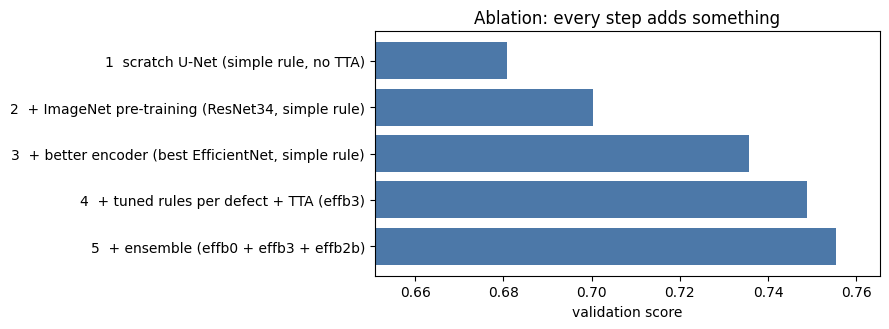

In [20]:
best_single = max(names, key=lambda k: CAND[k]["metrics"]["score"])
abl = pd.DataFrame([
    ("1  scratch U-Net (simple rule, no TTA)",                          RESULTS["scratch"]["score"]  if "scratch"  in RESULTS else np.nan),
    ("2  + ImageNet pre-training (ResNet34, simple rule)",              RESULTS["resnet34"]["score"] if "resnet34" in RESULTS else np.nan),
    ("3  + better encoder (best EfficientNet, simple rule)",            max(RESULTS[n]["score"] for n in names)),
    (f"4  + tuned rules per defect + TTA ({best_single})",              CAND[best_single]["metrics"]["score"]),
    (f"5  + ensemble ({best_name})",                                    FINAL_VAL["score"]),
], columns=["step", "validation score"]).set_index("step")
abl["gain vs previous row"] = abl["validation score"].diff().round(4)
abl["validation score"] = abl["validation score"].round(4)
display(abl); abl.to_csv(f"{OUT_DIR}/table3_ablation.csv")
plt.figure(figsize=(9, 3.4)); plt.barh(list(abl.index)[::-1], list(abl["validation score"])[::-1], color="#4c78a8"); plt.xlim(max(0, abl["validation score"].min() - 0.03), abl["validation score"].max() + 0.01)
plt.xlabel("validation score"); plt.title("Ablation: every step adds something"); plt.tight_layout(); plt.show()

## 10. Predict the test images and write `submission.csv`
For every test image: run the chosen model(s) with TTA → average → apply the tuned rules → **encode as RLE**.
Rows are written in exactly the order of `sample_submission.csv` (`ID, image_id, defect_type, mask_rle`; an empty mask is a single space, like in the sample).

  0%|          | 0/3000 [00:00<?, ?it/s]

predicting test images:   0%|          | 0/94 [00:00<?, ?it/s]

✅ saved /kaggle/working/submission.csv | 12000 rows | columns ['ID', 'image_id', 'defect_type', 'mask_rle']

% of (image, defect) pairs predicted NON-empty:
defect_type       defect_a  defect_b  defect_c  defect_d
test predictions      19.4       9.4      56.6      36.2
val predictions       12.9       4.8      48.5      17.5
train labels           9.5       2.7      36.0      15.0
(if 'test predictions' is far above 'val predictions' the test set is shifted / harder than validation - that explains a leaderboard score below the validation score)


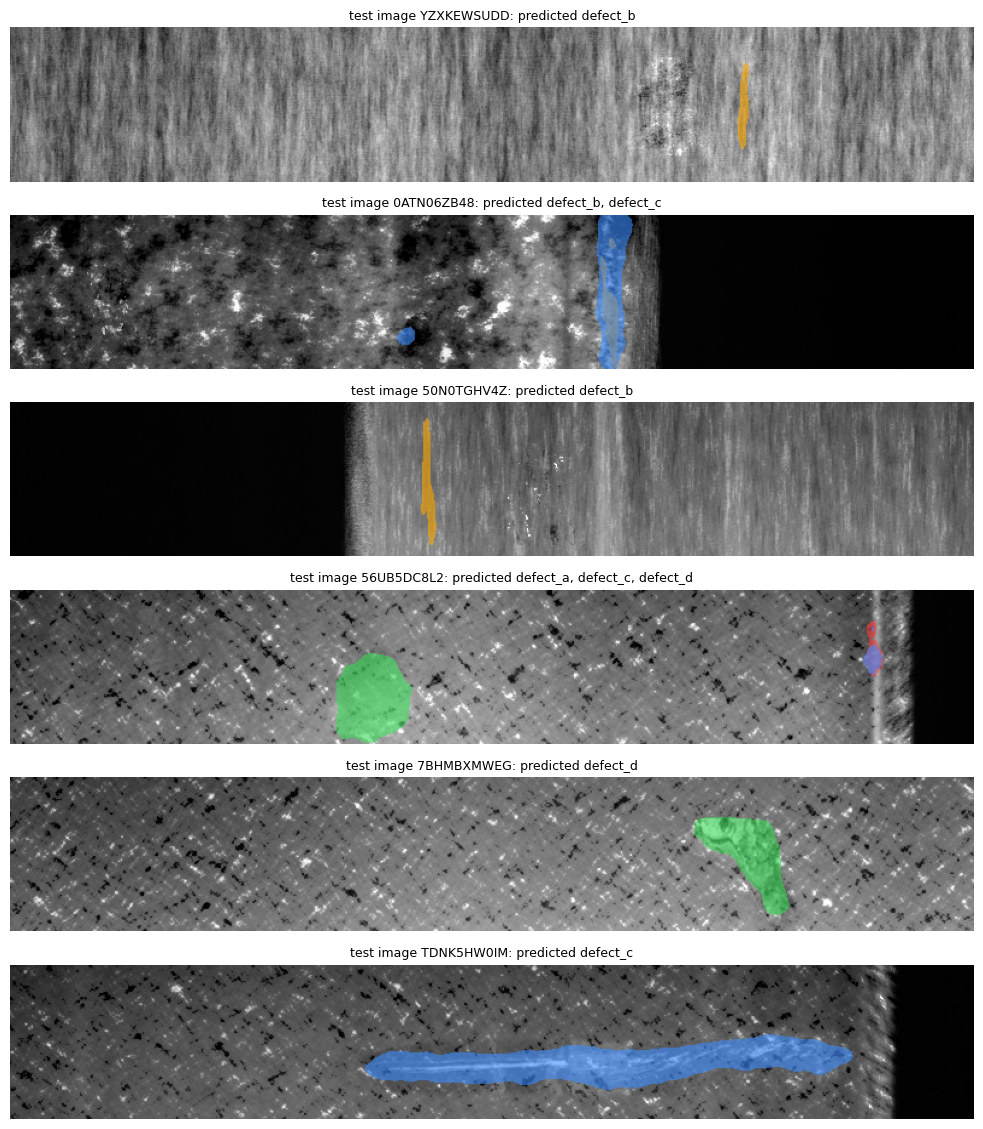

In [21]:
test_ids_all = list(dict.fromkeys(sample_df.image_id))
assert all(i in TEST_PATHS for i in test_ids_all), "some test images of sample_submission.csv are missing in the test folder"
test_ids    = test_ids_all[:QUICK_TEST_N] if QUICK_TEST else test_ids_all
test_images = load_many(test_ids, TEST_PATHS)

final_models, rle_rows, shown = [MODELS[m].eval() for m in best_members], {}, []
for s in tqdm(range(0, len(test_ids), 32), desc="predicting test images"):
    batch_ids = test_ids[s:s + 32]
    x = normalize_batch(np.stack([test_images[i] for i in batch_ids])).to(device)
    prob = sum(predict_batch(m, x) for m in final_models) / len(final_models)          # ensemble + TTA
    pred = postprocess(prob, rules["thr"], rules["min_area"], rules["gate"]).cpu().numpy().astype(np.uint8)
    for b, iid in enumerate(batch_ids):
        for c, cls in enumerate(CLASSES): rle_rows[(iid, cls)] = mask_to_rle(pred[b, c])
        if pred[b].any() and len(shown) < 6: shown.append(iid)

sub = sample_df.copy()
sub["mask_rle"] = [(rle_rows.get((i, c), "") or " ") for i, c in zip(sub.image_id, sub.defect_type)]
sub[["ID", "image_id", "defect_type", "mask_rle"]].to_csv(f"{OUT_DIR}/submission.csv", index=False)

check = pd.read_csv(f"{OUT_DIR}/submission.csv", keep_default_na=False)            # read it back and verify the format
assert list(check.columns) == list(sample_df.columns) and len(check) == len(sample_df) and (check.ID.values == sample_df.ID.values).all()
print(f"✅ saved {OUT_DIR}/submission.csv | {len(check)} rows | columns {list(check.columns)}")
_, pa_v, _ = stats_from_probs(best_probs, val_gt, rules["thr"], rules["min_area"], rules["gate"])             # same rule on the validation images
print("\n% of (image, defect) pairs predicted NON-empty:")
print(pd.DataFrame({"test predictions": (check.mask_rle.str.strip() != "").groupby(check.defect_type).mean() * 100, "val predictions": (pa_v > 0).mean(0) * 100, "train labels": has.mean().values * 100}).round(1).T.to_string())
print("(if 'test predictions' is far above 'val predictions' the test set is shifted / harder than validation - that explains a leaderboard score below the validation score)")

if shown:                                                                           # decode our own RLE and draw it on the test photos
    fig, axes = plt.subplots(len(shown), 1, figsize=(14, 1.9 * len(shown))); axes = np.atleast_1d(axes)
    for ax, iid in zip(axes, shown):
        rgb, names = np.stack([test_images[iid]] * 3, -1).copy(), []
        for c, cls in enumerate(CLASSES):
            m = rle_to_mask(check[(check.image_id == iid) & (check.defect_type == cls)].mask_rle.iloc[0])
            if m.any(): rgb[m == 1] = (0.4 * rgb[m == 1] + 0.6 * np.array(COLORS[c])).astype(np.uint8); names.append(cls)
        ax.imshow(rgb); ax.axis("off"); ax.set_title(f"test image {iid}: predicted {', '.join(names)}", fontsize=9)
    plt.tight_layout(); plt.show()

**Submit:** *Save Version → Save & Run All (Commit)* → Output tab → **Submit to competition**.

## 11. Error analysis (report: what does the model miss, and what does it invent?)

,true cases,missed completely (%),mean Dice (all true cases),false alarms (% of empty cases),median true area (px)
defect,,,,,
defect_a,216,26.4,0.480,6.5,472
defect_b,63,23.8,0.478,2.8,630
defect_c,820,4.0,0.675,21.8,2333
defect_d,342,5.0,0.778,3.8,4910


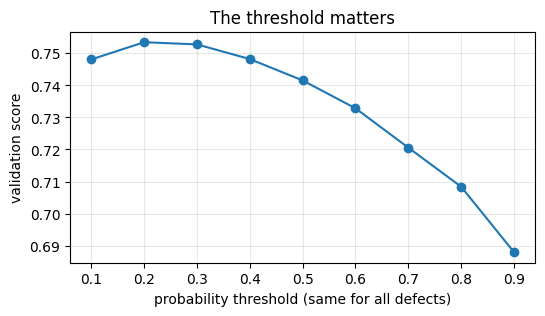

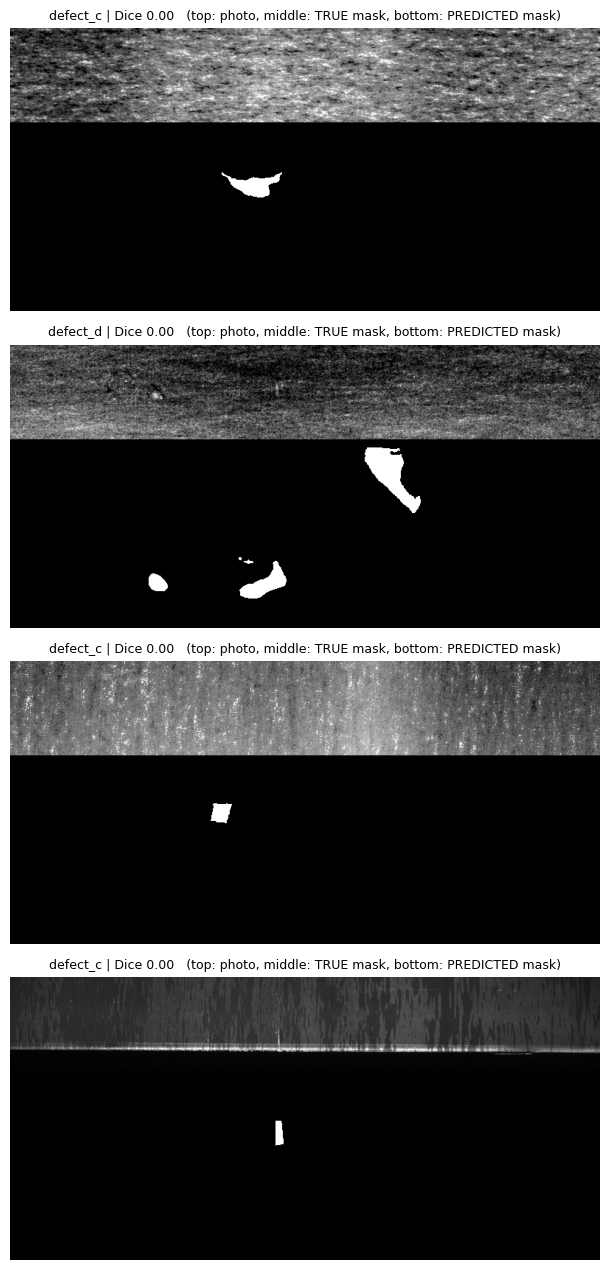

In [22]:
inter, pa, ga = stats_from_probs(best_probs, val_gt, rules["thr"], rules["min_area"], rules["gate"])
dice = np.where(ga > 0, 2 * inter / np.maximum(pa + ga, 1), np.nan)
rows = []
for c, cls in enumerate(CLASSES):
    fg, empty = ga[:, c] > 0, ga[:, c] == 0
    rows.append({"defect": cls, "true cases": int(fg.sum()), "missed completely (%)": round(100 * float((pa[fg, c] == 0).mean()), 1) if fg.any() else 0,
                 "mean Dice (all true cases)": round(float(np.nanmean(dice[:, c])), 3) if fg.any() else 0,
                 "false alarms (% of empty cases)": round(100 * float((pa[empty, c] > 0).mean()), 1) if empty.any() else 0,
                 "median true area (px)": int(np.median(ga[fg, c])) if fg.any() else 0})
display(pd.DataFrame(rows).set_index("defect"))

# effect of the decision threshold on the final score (rules otherwise fixed) -> a figure for the report
sweep = [competition_score(*stats_from_probs(best_probs, val_gt, t, rules["min_area"], rules["gate"]))["score"] for t in np.arange(0.1, 0.95, 0.1)]
plt.figure(figsize=(6, 3)); plt.plot(np.arange(0.1, 0.95, 0.1), sweep, marker="o"); plt.xlabel("probability threshold (same for all defects)")
plt.ylabel("validation score"); plt.title("The threshold matters"); plt.grid(alpha=0.3); plt.show()

# the 4 hardest big defects: photo / TRUE mask / PREDICTED mask
big = np.where(ga >= 300, np.nan_to_num(dice, nan=9), 9); order = np.dstack(np.unravel_index(np.argsort(big.ravel())[:4], big.shape))[0]
fig, axes = plt.subplots(len(order), 1, figsize=(14, 3.2 * len(order))); axes = np.atleast_1d(axes)
for ax, (k, c) in zip(axes, order):
    pred = postprocess(best_probs[k:k + 1].to(device), rules["thr"], rules["min_area"], rules["gate"])[0, c].cpu().numpy().astype(np.uint8)
    panel = np.vstack([np.stack([images[val_ids[k]]] * 3, -1), np.stack([val_gt[k, c].numpy() * 255] * 3, -1).astype(np.uint8), np.stack([pred * 255] * 3, -1).astype(np.uint8)])
    ax.imshow(panel); ax.axis("off"); ax.set_title(f"{CLASSES[c]} | Dice {big[k, c]:.2f}   (top: photo, middle: TRUE mask, bottom: PREDICTED mask)", fontsize=9)
plt.tight_layout(); plt.show()

## 12. Reproducibility + rubric self-check (gates for the L2 viva)

In [23]:
import importlib.metadata as md_                                         # write requirements.txt (reproducibility)
lines = []
for pkg in ["torch", "torchvision", "numpy", "pandas", "opencv-python", "opencv-python-headless", "scikit-learn", "matplotlib", "wandb", "tqdm"]:
    try: lines.append(f"{pkg}=={md_.version(pkg)}")
    except md_.PackageNotFoundError: pass
open(f"{OUT_DIR}/requirements.txt", "w").write("\n".join(lines) + "\n")
print(open(f"{OUT_DIR}/requirements.txt").read(), "| files:", sorted(os.listdir(OUT_DIR)))

torch==2.11.0+cu128
torchvision==0.26.0+cu128
numpy==2.1.3
pandas==2.3.3
opencv-python==4.14.0.94
opencv-python-headless==4.14.0.94
scikit-learn==1.6.1
matplotlib==3.10.0
wandb==0.28.1
tqdm==4.67.3
 | files: ['__notebook__.ipynb', 'effb0_best.pth', 'effb2_best.pth', 'effb2b_best.pth', 'effb3_best.pth', 'final_rules.json', 'requirements.txt', 'resnet34_best.pth', 'scratch_best.pth', 'submission.csv', 'table1_models.csv', 'table2_ensembles.csv', 'table3_ablation.csv', 'wandb']


In [24]:
# ---------- automatic self-check of the evaluation gates ----------
ok_all = True
def chk(ok, msg):
    global ok_all; ok_all &= bool(ok); print(("✅ " if ok else "❌ ") + msg)

chk(len(RESULTS) >= 3, f">= 3 models evaluated in this notebook: {list(RESULTS)}")
chk("scratch" in RESULTS, "one SCRATCH model (random weights) is in this notebook")
chk(any(n != "scratch" for n in RESULTS), "at least one PRETRAINED model is in this notebook")
chk(all(len(h) > 1 for h in HISTORY.values()) and len(HISTORY) >= 1, f"learning curves exist for the models trained here: {list(HISTORY)}")
sub_chk = pd.read_csv(f"{OUT_DIR}/submission.csv", keep_default_na=False)
chk(len(sub_chk) == len(sample_df), f"submission.csv has {len(sub_chk)} rows (expected {len(sample_df)})")
chk(os.path.exists(f"{OUT_DIR}/requirements.txt"), "requirements.txt written")
try:                                                                     # count the W&B runs of this project through the API
    api = wandb.Api(); ent = api.default_entity
    runs = [r for r in api.runs(f"{ent}/{WANDB_PROJECT}") if r.state == "finished" and len(r.summary.keys()) > 3]
    chk(len(runs) >= 3, f">= 3 valid (finished, with logged metrics) W&B runs in {ent}/{WANDB_PROJECT}: found {len(runs)}")
    print("   runs:", sorted(r.name for r in runs))
except Exception as e:
    chk(False, f"could not read W&B runs ({repr(e)[:90]}) - open https://wandb.ai and check the project by hand")
print("\n" + ("🎓 all automatic gates passed" if ok_all else "⚠️ fix the ❌ lines above before submitting"))
print("\nStill to do by hand (cannot be checked from a notebook):")
for t in ["GitHub repo public/shared, README.md + requirements.txt + notebooks/ + scripts/ present",
          "commit history: >= 8 meaningful commits spread over several days (see SCORING_GUIDE.md)",
          "notebook shared (private) with dlgenaiproject, 'Save & Run All (Commit)' finished, submission made",
          "project report (5-6 pages) written with the numbers printed above, PDF uploaded",
          "viva: you can explain every cell and write dice / rle / Dataset / postprocess live (Section 13)"]:
    print("  ☐", t)

✅ >= 3 models evaluated in this notebook: ['scratch', 'resnet34', 'effb0', 'effb2', 'effb3', 'effb2b']
✅ one SCRATCH model (random weights) is in this notebook
✅ at least one PRETRAINED model is in this notebook
✅ learning curves exist for the models trained here: ['scratch', 'resnet34', 'effb0', 'effb2', 'effb3', 'effb2b']
✅ submission.csv has 12000 rows (expected 12000)
✅ requirements.txt written
✅ >= 3 valid (finished, with logged metrics) W&B runs in iitm-mcq-sai/23f3001567-t32026: found 44
   runs: ['final_comparison', 'final_comparison_v2', 'final_comparison_v2', 'final_comparison_v2', 'final_comparison_v3', 'final_comparison_v4', 'final_comparison_v5', 'm1-unet-scratch-baseline', 'm1_unet_scratch', 'm1_unet_scratch', 'm3_effb0', 'm3_resnet34', 'm3_scratch', 'm4_R0', 'm4_R0', 'm4_R0b', 'm4_R1_warmup_cosine', 'm4_R2_sqrt_sampler', 'model1_scratch', 'model1_scratch_unet', 'model1_scratch_v4', 'model1_scratch_v5', 'model2_resnet34', 'model2_resnet34_v4', 'model2_resnet34_v5', 'model

## 13. Report guide, GitHub plan and viva notes

### Project report — what to write and where the numbers come from (5–6 pages)
| Report section | Content | Source in this notebook |
|---|---|---|
| 1 Problem statement | defect segmentation, 4 types, RLE, score = 0.7·Dice + 0.2·FP + 0.1·EmptyAcc | title cell, Section 3 |
| 2 Dataset & EDA | 11 393 train images 128×800, 48.4 % fully clean, 84 % empty (image, defect) pairs, defect_b only 2.7 %, class-imbalance figure, example masks | Section 2 |
| 3 Method | stratified split, augmentation, weighted sampler, loss, AdamW + warm-up + cosine, EMA, AMP | Sections 2, 4, 6 |
| 4 Models | scratch U-Net, ResNet34-U-Net, EfficientNet-B0/B2/B3-U-Nets (encoder–decoder, skip connections, grayscale trick) | Section 5 |
| 5 Experiments | W&B runs (screenshot of the project), learning curves, **Table 1** (all models), scratch-vs-pretrained bar chart | Sections 7, 8 |
| 6 Improvements / ablation | **Table 3 (ablation)**, tuned thresholds / min-area / confidence gate, TTA, ensemble **Table 2**, threshold figure | Sections 4, 9, 11 |
| 7 Iterations | 0.64888 → 0.68774 → **0.69878** (Kaggle Versions 3, 4, 5), with the reason for each jump | title cell |
| 8 Error analysis | missed-defect / false-alarm table, 4 failure examples, **validation-vs-test firing rates** (test is harder) | Sections 10, 11 |
| 9 Conclusion / future work | bigger encoders, longer training, image-level classifier, focal/Lovász loss, pseudo-labels on the test set | — |

### Commit history (GitHub) — the evaluator wants *steady progress*
Make real, small commits as you work, each with a meaningful message (e.g. `data loading + RLE`, `dataset & augmentation`, `scratch U-Net`, `pretrained U-Nets`, `W&B logging`, `threshold tuning`, `ensemble + TTA`, `submission`, `report`). Spread them over several days. Do **not** upload the dataset or the `.pth` weights.

### Viva notes — explain it in your own words
- **Why U-Net?** encoder = what, decoder = where, skip connections keep the detail. **Why pretrained?** it already learned edges and textures from ImageNet → learns faster and better than from scratch (see the scratch-vs-pretrained bar chart: *quote your own numbers*).
- **Why sigmoid with 4 outputs?** a pixel can be "none" or any defect; 4 independent yes/no answers. **Why BCE + Dice?** BCE = per-pixel correctness, Dice = shape overlap; the per-pair Dice term matches the 70 % of the score that measures Dice on defective pairs.
- **Why not pixel accuracy?** predicting "no defect" everywhere already gives > 99 %. Use Dice / F1 / the competition score. Predict-nothing scores 0.30.
- **Why tune the threshold and minimum area?** 84 % of pairs are empty, a false alarm costs points, and the best cut-off differs per defect (our tuned thresholds: 0.20 / 0.05 / 0.25 / 0.35).
- **What is the confidence gate?** A mask is kept only if its most confident pixel reaches the gate. A low pixel threshold makes masks complete (better Dice) and the gate removes weak blobs on clean images (fewer false alarms) — two jobs, two numbers.
- **Why does an ensemble help?** Different models make different mistakes; the average cancels part of them (single models 0.729 – 0.736 → ensemble 0.755 on validation).
- **Why is the leaderboard (0.699) below validation (0.755)?** (a) rules and epochs were chosen on the validation images → slightly optimistic; (b) the test set fires 1.5 – 3 × more often than validation → harder/shifted. The gap (≈ 0.059) was identical in three notebooks, so it is systematic, not luck.
- **What is EMA / TTA?** EMA = averaged weights (smoother, generalise better). TTA = average of 4 flipped views.
- **Over-fitting?** augmentation, weight decay, validation monitoring, best-epoch checkpoint, EMA.
- **Why ensemble B0 + B3 + B2 #2?** Different encoders and seeds make partly independent errors; averaging their probabilities lowers variance (best single tuned model 0.7489 → ensemble 0.7554).
- **Why were all models retrained in the final run?** The weights of earlier runs were not attached as inputs, so the notebook trained all six models again (≈ 5 h on a T4). Results moved only slightly, which shows the run-to-run noise.

### Live-coding practice (typical things to write on the spot)
```python
def dice(pred, true):                                 # pred, true = 0/1 numpy arrays
    inter = (pred * true).sum()
    total = pred.sum() + true.sum()
    return 2 * inter / total if total > 0 else 1.0

def postprocess(prob, thr=0.4, min_area=40):          # prob: (H, W) probabilities -> 0/1 mask
    mask = prob > thr
    return mask if mask.sum() >= min_area else mask * 0
```
Also practise `rle_to_mask`, `mask_to_rle` (column-major, 1-based!), a tiny `Dataset` with `__len__` / `__getitem__`, and a training loop (forward → loss → backward → step). The same functions are in `scripts/rle_metric.py` with tests.
